# Transportation Project

AbbasEbrahimi-401101076

MahanKazemi

AmirmahdiBigdeli




## Data Study

First we open the data to see the data types and attributes.

### Attributes:

In [1]:
import pandas as pd
data = pd.read_csv('rideshare_kaggle.csv')


In [2]:
data.head()


,id,hour,day,month,source,destination,cab_type,product_id,name,price,...,pressure,windBearing,cloudCover,uvIndex,ozone,moonPhase,temperatureMin,temperatureMax,apparentTemperatureMin,apparentTemperatureMax
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,9,16,12,Haymarket Square,North Station,Lyft,lyft_line,Shared,5.0,...,1021.98,57,0.72,0,303.8,0.30,39.89,43.68,33.73,38.07
1,4bd23055-6827-41c6-b23b-3c491f24e74d,2,27,11,Haymarket Square,North Station,Lyft,lyft_premier,Lux,11.0,...,1003.97,90,1.00,0,291.1,0.64,40.49,47.30,36.20,43.92
2,981a3613-77af-4620-a42a-0c0866077d1e,1,28,11,Haymarket Square,North Station,Lyft,lyft,Lyft,7.0,...,992.28,240,0.03,0,315.7,0.68,35.36,47.55,31.04,44.12
3,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,4,30,11,Haymarket Square,North Station,Lyft,lyft_luxsuv,Lux Black XL,26.0,...,1013.73,310,0.00,0,291.1,0.75,34.67,45.03,30.30,38.53
4,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,3,29,11,Haymarket Square,North Station,Lyft,lyft_plus,Lyft XL,9.0,...,998.36,303,0.44,0,347.7,0.72,33.10,42.18,29.11,35.75


The dataset represents detailed information about ride-hailing trips, combining
three major types of data: temporal attributes, transportation attributes, and
weather conditions. Each row corresponds to an individual ride option offered by
a ride-hailing service (Lyft or Uber) at a specific time and location.

1. Temporal Features
- hour: The hour of the day when the ride information was recorded.
- day: Day of the month.
- month: Month of the year.
These columns are useful for analyzing time-based pricing patterns, identifying
peak hours, and studying seasonality or weekly behavior.

2. Spatial Features
- source: Starting location of the trip.
- destination: Ending location of the trip.
These are categorical variables representing demand corridors in the city.
They allow route-based analysis of pricing differences or travel patterns.

3. Ride and Service Attributes
- cab_type: The company providing the service (Lyft or Uber).
- product_id: Internal service identifier (e.g., lyft_line, lyft_plus).
- name: Human-readable service type (e.g., Shared, Lyft XL, Lux).
- price: The price of the ride option shown to the user.
- distance: Trip distance in miles.
- surge_multiplier: The surge pricing factor applied to that ride.
These columns capture the core economic and operational aspects of the service.
Different service types (Shared, Lux, XL) naturally exhibit different price
levels. Surge pricing is used to reflect real-time supply-demand imbalance.

4. Weather and Environmental Conditions
The dataset includes detailed real-time weather data at the moment the ride
information was recorded:
- temperature, apparentTemperature
- short_summary, long_summary
- precipIntensity, precipProbability
- humidity
- windSpeed, windGust
- visibility
- cloudCover, pressure, dewPoint, ozone, moonPhase
- temperatureMin, temperatureMax, apparentTemperatureMin, apparentTemperatureMax



In [3]:

data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Data columns (total 39 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       693071 non-null  object 
 1   hour                     693071 non-null  int64  
 2   day                      693071 non-null  int64  
 3   month                    693071 non-null  int64  
 4   source                   693071 non-null  object 
 5   destination              693071 non-null  object 
 6   cab_type                 693071 non-null  object 
 7   product_id               693071 non-null  object 
 8   name                     693071 non-null  object 
 9   price                    637976 non-null  float64
 10  distance                 693071 non-null  float64
 11  surge_multiplier         693071 non-null  float64
 12  latitude                 693071 non-null  float64
 13  longitude                693071 non-null  float64
 14  temp

,hour,day,month,price,distance,surge_multiplier,latitude,longitude,temperature,apparentTemperature,...,pressure,windBearing,cloudCover,uvIndex,ozone,moonPhase,temperatureMin,temperatureMax,apparentTemperatureMin,apparentTemperatureMax
count,693071.000000,693071.000000,693071.000000,637976.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,...,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000
mean,11.619137,17.794365,11.586684,16.545125,2.189430,1.013870,42.338172,-71.066151,39.584388,35.881222,...,1010.094766,220.055853,0.686502,0.248908,313.513635,0.579066,33.457774,45.261313,29.731002,41.997343
std,6.948114,9.982286,0.492429,9.324359,1.138937,0.091641,0.047840,0.020302,6.726084,7.918707,...,13.472899,99.102736,0.358534,0.474097,27.953061,0.244705,6.467224,5.645046,7.110494,6.936841
min,0.000000,1.000000,11.000000,2.500000,0.020000,1.000000,42.214800,-71.105400,18.910000,12.130000,...,988.090000,2.000000,0.000000,0.000000,269.400000,0.090000,15.630000,33.510000,11.810000,28.950000
25%,6.000000,13.000000,11.000000,9.000000,1.280000,1.000000,42.350300,-71.081000,36.450000,31.910000,...,999.820000,124.000000,0.370000,0.000000,290.900000,0.300000,30.170000,42.570000,27.760000,36.570000
50%,12.000000,17.000000,12.000000,13.500000,2.160000,1.000000,42.351900,-71.063100,40.490000,35.900000,...,1009.250000,258.000000,0.820000,0.000000,307.400000,0.680000,34.240000,44.680000,30.130000,40.950000
75%,18.000000,28.000000,12.000000,22.500000,2.920000,1.000000,42.364700,-71.054200,43.580000,40.080000,...,1021.860000,303.000000,1.000000,0.000000,331.800000,0.790000,38.880000,46.910000,35.710000,44.120000
max,23.000000,30.000000,12.000000,97.500000,7.860000,3.000000,42.366100,-71.033000,57.220000,57.220000,...,1035.550000,356.000000,1.000000,2.000000,378.900000,0.930000,43.100000,57.870000,40.050000,57.200000


### Origins and destinations analysis:

In [4]:
data["source"].unique()


array(['Haymarket Square', 'Back Bay', 'North End', 'North Station',
       'Beacon Hill', 'Boston University', 'Fenway', 'South Station',
       'Theatre District', 'West End', 'Financial District',
       'Northeastern University'], dtype=object)

In [5]:

data["destination"].unique()

array(['North Station', 'Northeastern University', 'West End',
       'Haymarket Square', 'South Station', 'Fenway', 'Theatre District',
       'Beacon Hill', 'Back Bay', 'North End', 'Financial District',
       'Boston University'], dtype=object)

The above result are $Sources$ and $Destinations$.(are same list)

Now we make a matrix to see the amount of trips between nodes.

In [6]:
od_matrix = pd.crosstab(data['source'], data['destination'])

print("Origin–Destination Trip Count Matrix:")
display(od_matrix)

Origin–Destination Trip Count Matrix:


destination,Back Bay,Beacon Hill,Boston University,Fenway,Financial District,Haymarket Square,North End,North Station,Northeastern University,South Station,Theatre District,West End
source,,,,,,,,,,,,
Back Bay,0,0,9435,9469,0,9605,10225,0,9584,9474,0,0
Beacon Hill,0,0,9222,9436,0,9566,10039,0,9684,9456,0,0
Boston University,9435,9215,0,0,9711,0,0,9480,0,0,9967,9956
Fenway,9476,9436,0,0,9681,0,0,9751,0,0,9248,10165
Financial District,0,0,9711,9695,0,10133,9339,0,9627,10352,0,0
Haymarket Square,9605,9566,0,0,10134,0,0,9634,0,0,9641,9156
North End,10225,10039,0,0,9339,0,0,9422,0,0,9525,9213
North Station,0,0,9480,9751,0,9641,9421,0,9679,9146,0,0
Northeastern University,9579,9690,0,0,9634,0,0,9679,0,0,9644,9530


Above is matrix of trips form origin to destination, now we find most frequent OD pairs.

In [7]:
od_flat = od_matrix.stack().reset_index()
od_flat.columns = ['source', 'destination', 'count']

top_n = od_flat.sort_values('count', ascending=False).head(5)
display(top_n)   

,source,destination,count
112,South Station,Financial District,10352
57,Financial District,South Station,10352
72,North End,Back Bay,10225
6,Back Bay,North End,10225
135,West End,Fenway,10165


Above are top 5 OD pairs.

#### Any Origin only node?

Now we want to find a node that is just origin to trips and not destination, as we see in the OD matrix and the list before, $destination$ and $source$ list are the same, that means there is no node that only produces trip.

### name and ID

It is asked that if we can use name and ID, yes of course wecan use them because the reveale more data and are relevant to out output logically, but can we use them together?

In [8]:
mapping = data.groupby(['product_id'])['name'].nunique()
display(mapping)


product_id
55c66225-fbe7-4fd5-9072-eab1ece5e23e    1
6c84fd89-3f11-4782-9b50-97c468b19529    1
6d318bcc-22a3-4af6-bddd-b409bfce1546    1
6f72dfc5-27f1-42e8-84db-ccc7a75f6969    1
8cf7e821-f0d3-49c6-8eba-e679c0ebcf6a    1
997acbb5-e102-41e1-b155-9df7de0a73f2    1
9a0e7b09-b92b-4c41-9779-2ad22b4d779d    1
lyft                                    1
lyft_line                               1
lyft_lux                                1
lyft_luxsuv                             1
lyft_plus                               1
lyft_premier                            1
Name: name, dtype: int64

Mapping result of 1 for all product_id's show that each product_id is corresponding to a name, meaning you exactly know the name knowing prosuct_id, so we don't use both in our analysis.

### Encoding

We have two ways to encode, one is 
#### Label encoding

$Label encoding$ gives a unique name a unique number, that makes it so easy to encode, you find unique names, then map each name to a number, attributes could be ordinal, meaning attribute has value, something like good, verygood and mindblowing, they can be encoded in numbers incrementally and preserve the value they had.
The problem with $Label encoding$ is that first if we want to use them for ordinal the number can't show the value like a name, and the second problem is that $Label encoding$ can't be used for nominal attributes, because the numbers representing the nominals give them a serial value that is absolutly wrong.


#### One-hot encoding

It is used in cases we have nominal attributes, converts each category into a binary vector (1 where the category exists, 0 otherwise) making each category independently representing its value in algorithm, it makes no artificial ordering, safe for most ML algorithms, but can create many columns if categories are many, increasing memory usage and harder than label encoding in implementing.

### Cleaning for future

Here we clean the data and impute missing values.

In [9]:
# Remove columns with more than 30% missing values
RideData = data.copy()

threshold = 0.30  # 30%
missing_ratio = RideData.isna().mean()   # ratio of missing values per column

cols_to_drop = missing_ratio[missing_ratio > threshold].index.tolist()

print("Columns removed due to >30% missing:")
print(cols_to_drop)
missing_ratio.sort_values(ascending=False)
print(missing_ratio)
RideData = RideData.drop(columns=cols_to_drop)


Columns removed due to >30% missing:
[]
id                         0.000000
hour                       0.000000
day                        0.000000
month                      0.000000
source                     0.000000
destination                0.000000
cab_type                   0.000000
product_id                 0.000000
name                       0.000000
price                      0.079494
distance                   0.000000
surge_multiplier           0.000000
latitude                   0.000000
longitude                  0.000000
temperature                0.000000
apparentTemperature        0.000000
short_summary              0.000000
long_summary               0.000000
precipIntensity            0.000000
precipProbability          0.000000
humidity                   0.000000
windSpeed                  0.000000
windGust                   0.000000
visibility                 0.000000
temperatureHigh            0.000000
temperatureLow             0.000000
apparentTemperatureHigh 

Missing values only exist in price, now we want to make a simple model to predict the missing values, because the missing is close to 5 percent, we make a simple model, the idea is to use mean for each $name$, not too complicated and still useful(because missing values are not many).

In [10]:
RideData.groupby('name')['price'].count()


name
Black           55095
Black SUV       55096
Lux             51235
Lux Black       51235
Lux Black XL    51235
Lyft            51235
Lyft XL         51235
Shared          51233
Taxi                0
UberPool        55091
UberX           55094
UberXL          55096
WAV             55096
Name: price, dtype: int64

In [11]:
from scipy.stats import f_oneway

#handle gropus with less than 2 values.
groups = [g['price'].dropna() for _, g in data.groupby('name') if len(g['price'].dropna()) > 1]
anova_result = f_oneway(*groups)

print(anova_result.pvalue)

0.0


Very low p-value shows that the $name$ is a very good attribute to group by, so we use mean of each category in $name$ column to fill the NA's.
One point here is that taxi has no price enterd, so we delete taxi rows first.

In [12]:
RideData = RideData[RideData['name'] != 'Taxi']
RideData['price'] = RideData.groupby('name')['price'].transform(
    lambda x: x.fillna(x.mean())
)


In [13]:

RideData['price'].isna().sum()

0

No na price now.

### Encoding name column

Because name is nominal and does not have value ordering, we use One-hot Label encoding: 

In [14]:
RideData = pd.get_dummies(RideData,columns=['name'], prefix='name', dtype=int , drop_first=True)

In [ ]:
RideData.info()

<class 'pandas.core.frame.DataFrame'>
Index: 637976 entries, 0 to 693070
Data columns (total 49 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       637976 non-null  object 
 1   hour                     637976 non-null  int64  
 2   day                      637976 non-null  int64  
 3   month                    637976 non-null  int64  
 4   source                   637976 non-null  object 
 5   destination              637976 non-null  object 
 6   cab_type                 637976 non-null  object 
 7   product_id               637976 non-null  object 
 8   price                    637976 non-null  float64
 9   distance                 637976 non-null  float64
 10  surge_multiplier         637976 non-null  float64
 11  latitude                 637976 non-null  float64
 12  longitude                637976 non-null  float64
 13  temperature              637976 non-null  float64
 14  apparentT

The data above is used frequently in this project to make prediction models.

## 2_1

In [ ]:
import pandas as pd
import statsmodels.api as sm


df = pd.read_csv('rideshare_kaggle.csv')


df_test = df[['name', 'price']].copy()


df_test = df_test[df_test['name'] != "Taxi"]


df_test['price'] = pd.to_numeric(df_test['price'], errors='coerce')
df_test = df_test.dropna(subset=['price', 'name'])


df_dummies = pd.get_dummies(df_test, columns=['name'], drop_first=True)


df_dummies = df_dummies.astype(float)


X = df_dummies.drop('price', axis=1)
y = df_dummies['price']

X = sm.add_constant(X)


model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.774
Model:                            OLS   Adj. R-squared:                  0.774
Method:                 Least Squares   F-statistic:                 1.989e+05
Date:                Fri, 05 Dec 2025   Prob (F-statistic):               0.00
Time:                        05:19:14   Log-Likelihood:            -1.8549e+06
No. Observations:              637976   AIC:                         3.710e+06
Df Residuals:                  637964   BIC:                         3.710e+06
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                20.5238      0.01

We convert the name variable into dummy variables and model price as a function of these indicators. Based on the adjusted R² value, the model demonstrates a relatively strong predictive performance. Furthermore, the p-values of the dummy variables show that all categories have a statistically significant effect on price. Therefore, price can be approximated well using the ride-category (name) variables.

In [ ]:
import pandas as pd
from scipy import stats



df_anova = df[['name', 'price']].copy()


df_anova = df_anova[df_anova['name'] != "Taxi"]


df_anova['price'] = pd.to_numeric(df_anova['price'], errors='coerce')
df_anova = df_anova.dropna(subset=['price', 'name'])


groups = [group["price"].values for name, group in df_anova.groupby("name")]


f_stat, p_value = stats.f_oneway(*groups)


anova_table = pd.DataFrame({
    "Source": ["Between Groups", "Within Groups", "Total"],
    "F-statistic": [f_stat, None, None],
    "p-value": [p_value, None, None],
    "Notes": [
        "Difference among group means",
        "Variation within groups",
        "Total variation"
    ]
})


print(anova_table)


           Source    F-statistic  p-value                         Notes
0  Between Groups  198877.843591      0.0  Difference among group means
1   Within Groups            NaN      NaN       Variation within groups
2           Total            NaN      NaN               Total variation


The ANOVA test shows that the mean prices are not equal across ride categories. The very small p-value indicates that the variable name has a statistically significant effect on price

## 2_2

In [ ]:
import pandas as pd
from statsmodels.stats.multicomp import pairwise_tukeyhsd


df_anova = df[['name', 'price']].copy()
df_anova = df_anova[df_anova['name'] != "Taxi"]
df_anova['price'] = pd.to_numeric(df_anova['price'], errors='coerce')
df_anova = df_anova.dropna(subset=['price', 'name'])


tukey = pairwise_tukeyhsd(endog=df_anova['price'],
                          groups=df_anova['name'],
                          alpha=0.05)


print(tukey.summary())


       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
   group1       group2    meandiff p-adj  lower    upper   reject
-----------------------------------------------------------------
       Black    Black SUV    9.763   0.0   9.6757   9.8502   True
       Black          Lux  -2.7525   0.0  -2.8414  -2.6637   True
       Black    Lux Black   2.5387   0.0   2.4498   2.6275   True
       Black Lux Black XL  11.8003   0.0  11.7114  11.8892   True
       Black         Lyft -10.9129   0.0 -11.0018  -10.824   True
       Black      Lyft XL  -5.2144   0.0  -5.3033  -5.1256   True
       Black       Shared -14.4939   0.0 -14.5828  -14.405   True
       Black     UberPool -11.7713   0.0 -11.8585  -11.684   True
       Black        UberX -10.7587   0.0  -10.846 -10.6715   True
       Black       UberXL  -4.8456   0.0  -4.9329  -4.7584   True
       Black          WAV -10.7588   0.0  -10.846 -10.6715   True
   Black SUV          Lux -12.5155   0.0 -12.6044 -12.4267   True
   Black S

Based on the results of the ANOVA test, we can see that there are significant differences in prices among the ride categories (name). To determine exactly which categories are responsible for these differences, we calculate the pairwise differences of the means between all possible pairs and examine which ones are statistically significant. This analysis is performed using the Tukey HSD test.
Null hypothesis (H0): The mean prices of all ride categories (name) are equal.
Alternative hypothesis (H1): At least one ride category has a different mean price.
Specifically, almost all pairs of ride categories differ significantly in their mean prices, except for the pair UberX and WAV, which do not show a significant difference. Therefore, the ride category (name) is an important factor influencing price

## 2_3

C:\Users\asus\AppData\Local\Temp\ipykernel_15772\327402162.py:38: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


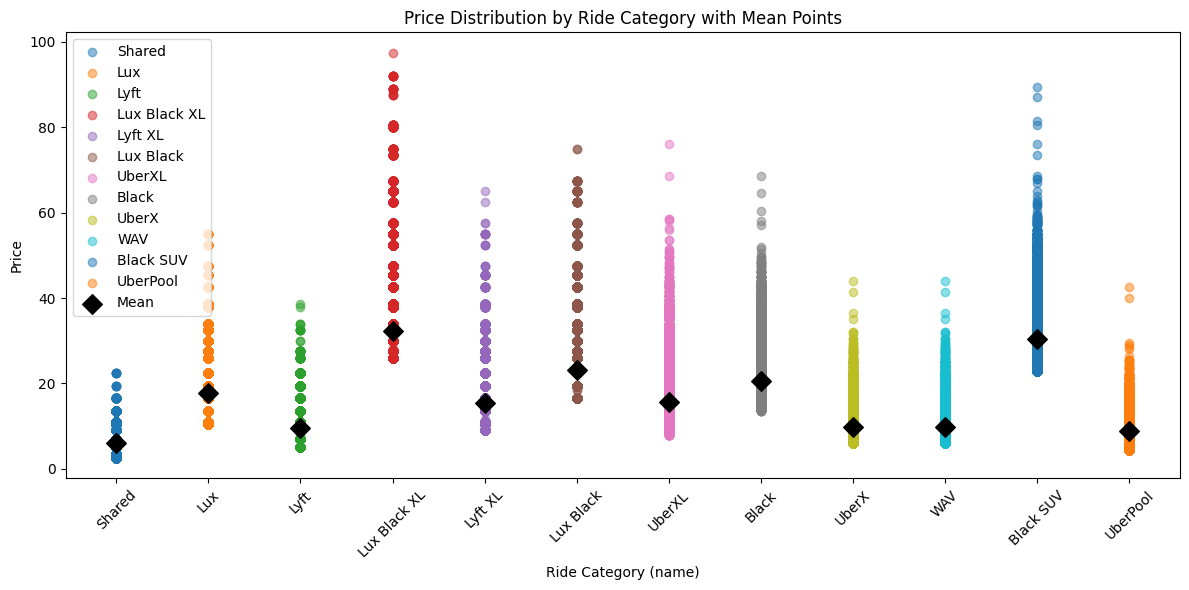

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


df_anova = df[['name', 'price']].copy()
df_anova = df_anova[df_anova['name'] != "Taxi"]
df_anova['price'] = pd.to_numeric(df_anova['price'], errors='coerce')
df_anova = df_anova.dropna(subset=['price', 'name'])


unique_names = df_anova['name'].unique()
name_to_x = {name: i for i, name in enumerate(unique_names)}
df_anova['x_pos'] = df_anova['name'].map(name_to_x)


group_means = df_anova.groupby('name')['price'].mean().reset_index()
group_means['x_pos'] = group_means['name'].map(name_to_x)


plt.figure(figsize=(12,6))


for name in unique_names:
    subset = df_anova[df_anova['name'] == name]
    plt.scatter(subset['x_pos'], subset['price'], alpha=0.5, label=name)


plt.scatter(group_means['x_pos'], group_means['price'], color='black', s=100, marker='D', label='Mean')


plt.xticks(ticks=list(name_to_x.values()), labels=list(name_to_x.keys()), rotation=45)
plt.ylabel('Price')
plt.xlabel('Ride Category (name)')
plt.title('Price Distribution by Ride Category with Mean Points')
plt.legend()
plt.tight_layout()
plt.show()


Based on the dispersion of the points, the mean price for each ride category (name) is located towards the lower part of the distribution, indicating that the price distribution for each category is not normal and is skewed to the left. The figure also shows that there are significant differences between the means of most categories. However, in some groups, such as UberX, WAV, and UberPool, the means appear visually close to each other and the variances are approximately similar.

## 2_4

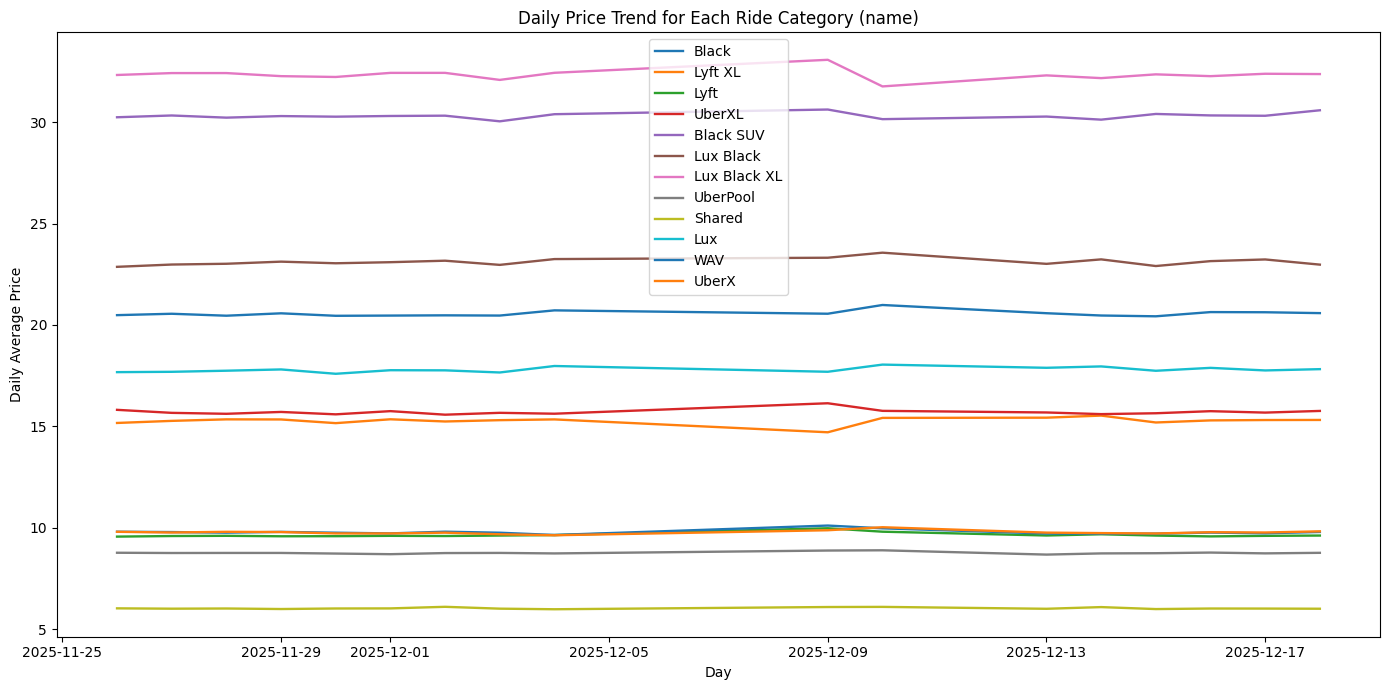

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df_daily = df[['name', 'price', 'day', 'month']].copy()


df_daily['price'] = pd.to_numeric(df_daily['price'], errors='coerce')
df_daily = df_daily.dropna(subset=['price'])


df_daily['date'] = pd.to_datetime(dict(year=2025, 
                                       month=df_daily['month'], 
                                       day=df_daily['day']))


df_mean_daily = df_daily.groupby(['name', 'date'])['price'].mean().reset_index()


df_mean_daily = df_mean_daily.sort_values('date')


plt.figure(figsize=(14,7))

names = df_mean_daily['name'].unique()

for name in names:
    temp = df_mean_daily[df_mean_daily['name'] == name]
    plt.plot(temp['date'], temp['price'], label=name, linewidth=1.7)

plt.xlabel("Day")
plt.ylabel("Daily Average Price")
plt.title("Daily Price Trend for Each Ride Category (name)")
plt.legend()
plt.tight_layout()
plt.show()


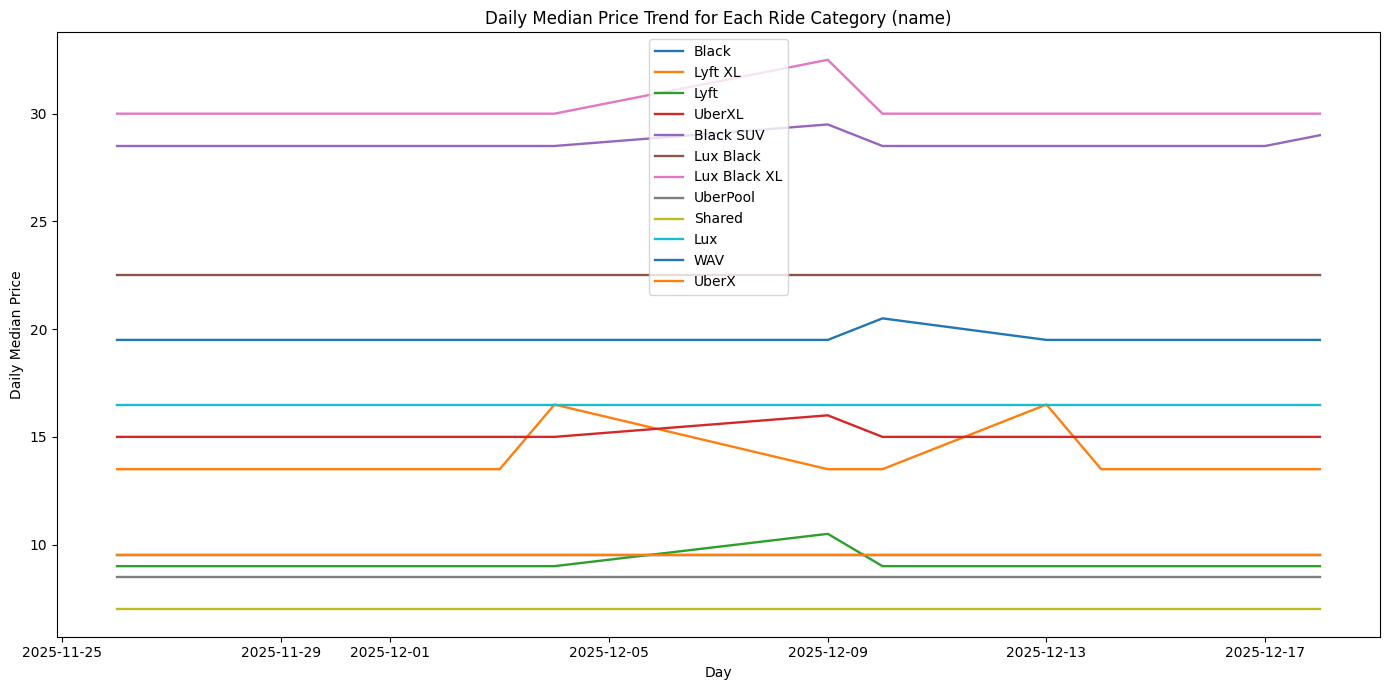

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df_daily = df[['name', 'price', 'day', 'month']].copy()


df_daily['price'] = pd.to_numeric(df_daily['price'], errors='coerce')
df_daily = df_daily.dropna(subset=['price'])


df_daily['date'] = pd.to_datetime(dict(
    year=2025,
    month=df_daily['month'],
    day=df_daily['day']
))


df_median_daily = df_daily.groupby(['name', 'date'])['price'].median().reset_index()


df_median_daily = df_median_daily.sort_values('date')


plt.figure(figsize=(14,7))

names = df_median_daily['name'].unique()

for name in names:
    temp = df_median_daily[df_median_daily['name'] == name]
    plt.plot(temp['date'], temp['price'], label=name, linewidth=1.7)

plt.xlabel("Day")
plt.ylabel("Daily Median Price")
plt.title("Daily Median Price Trend for Each Ride Category (name)")
plt.legend()
plt.tight_layout()
plt.show()


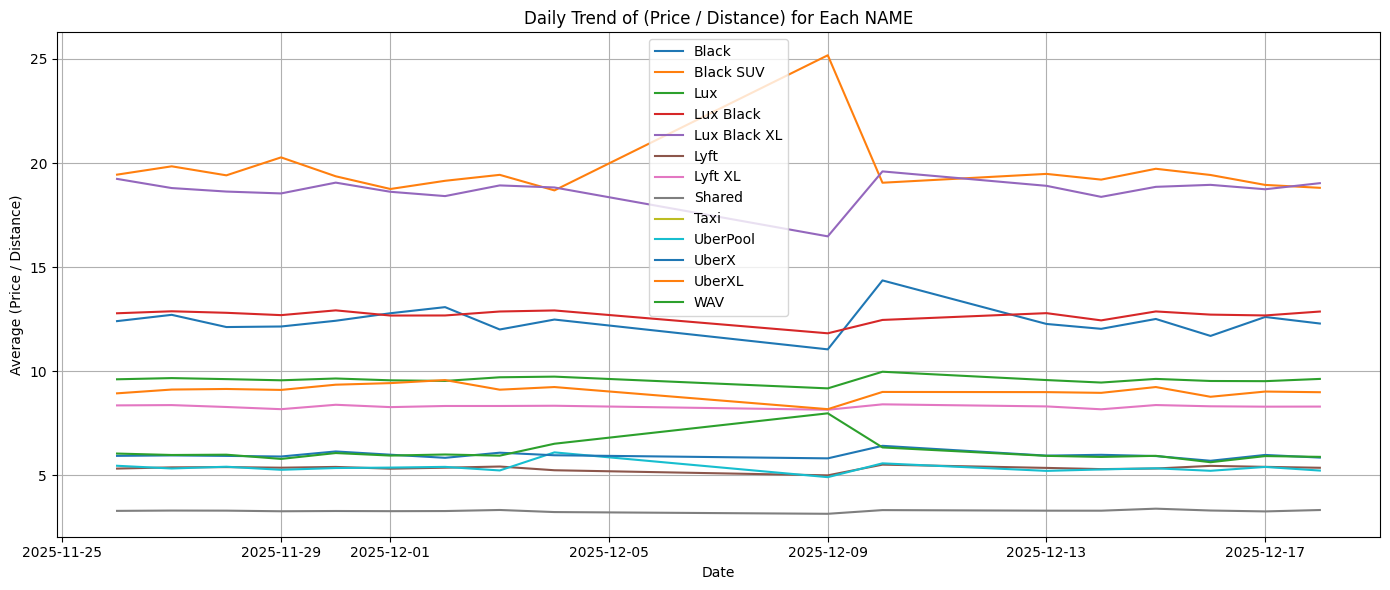

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df['price_per_distance'] = df['price'] / df['distance']


df['date'] = pd.to_datetime({
    'year': 2025,
    'month': df['month'],
    'day': df['day']
})


daily_avg = df.groupby(['name', 'date'])['price_per_distance'].mean().reset_index()


plt.figure(figsize=(14, 6))

for name in daily_avg['name'].unique():
    subset = daily_avg[daily_avg['name'] == name]
    plt.plot(subset['date'], subset['price_per_distance'], label=name)

plt.xlabel("Date")
plt.ylabel("Average (Price / Distance)")
plt.title("Daily Trend of (Price / Distance) for Each NAME")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Three plots were generated. The first two plots were created without considering distance: the first is based on the daily mean price, and the second is based on the daily median price.
The third plot is described below:

First, we divide the price by the distance to obtain the rate for each trip, allowing us to determine the daily rate for each transportation type. Then, we compute the average of all rates for each day. We observe that, overall, the trend shows very little variation, and the starting and ending points are almost the same across all groups. However, in the middle of the observed period, some increases and decreases appear for all groups, with the largest fluctuations seen in the BLACK SUV category.

## 2_5

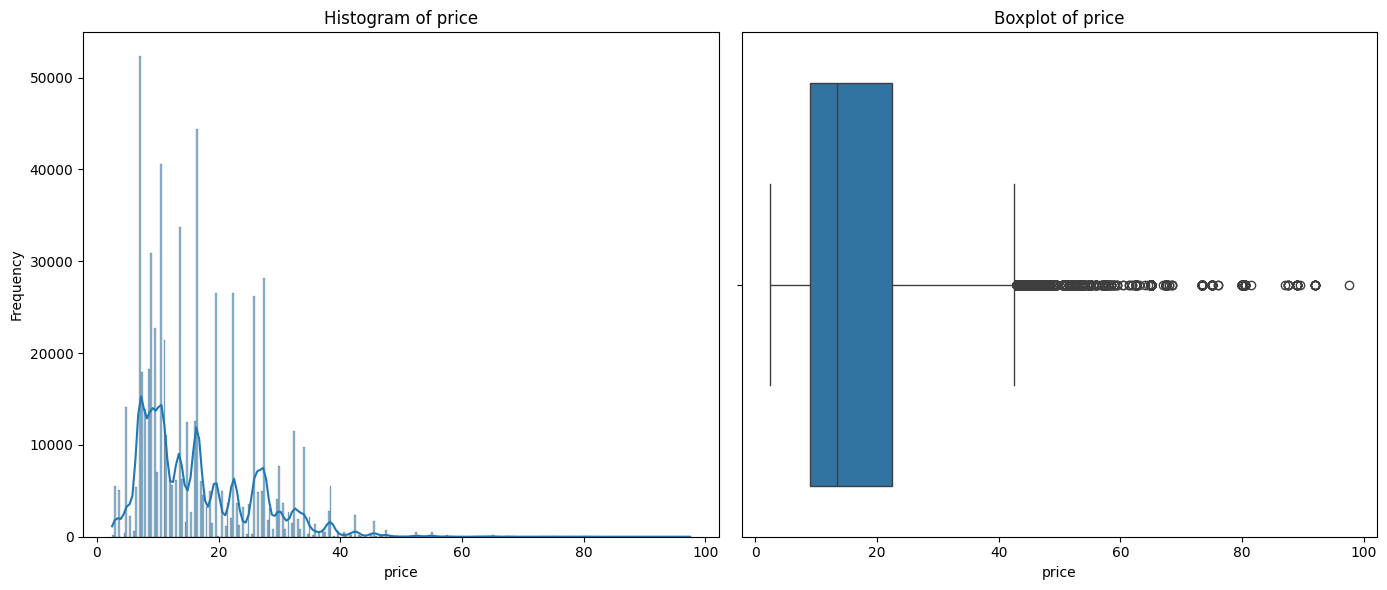

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd




df_clean = df.copy()
df_clean["price"] = pd.to_numeric(df_clean["price"], errors="coerce")
df_clean = df_clean.dropna(subset=["price"])

plt.figure(figsize=(14,6))


plt.subplot(1,2,1)
sns.histplot(df_clean["price"], kde=True)
plt.title("Histogram of price")
plt.xlabel("price")
plt.ylabel("Frequency")


plt.subplot(1,2,2)
sns.boxplot(x=df_clean["price"])
plt.title("Boxplot of price")
plt.xlabel("price")

plt.tight_layout()
plt.show()


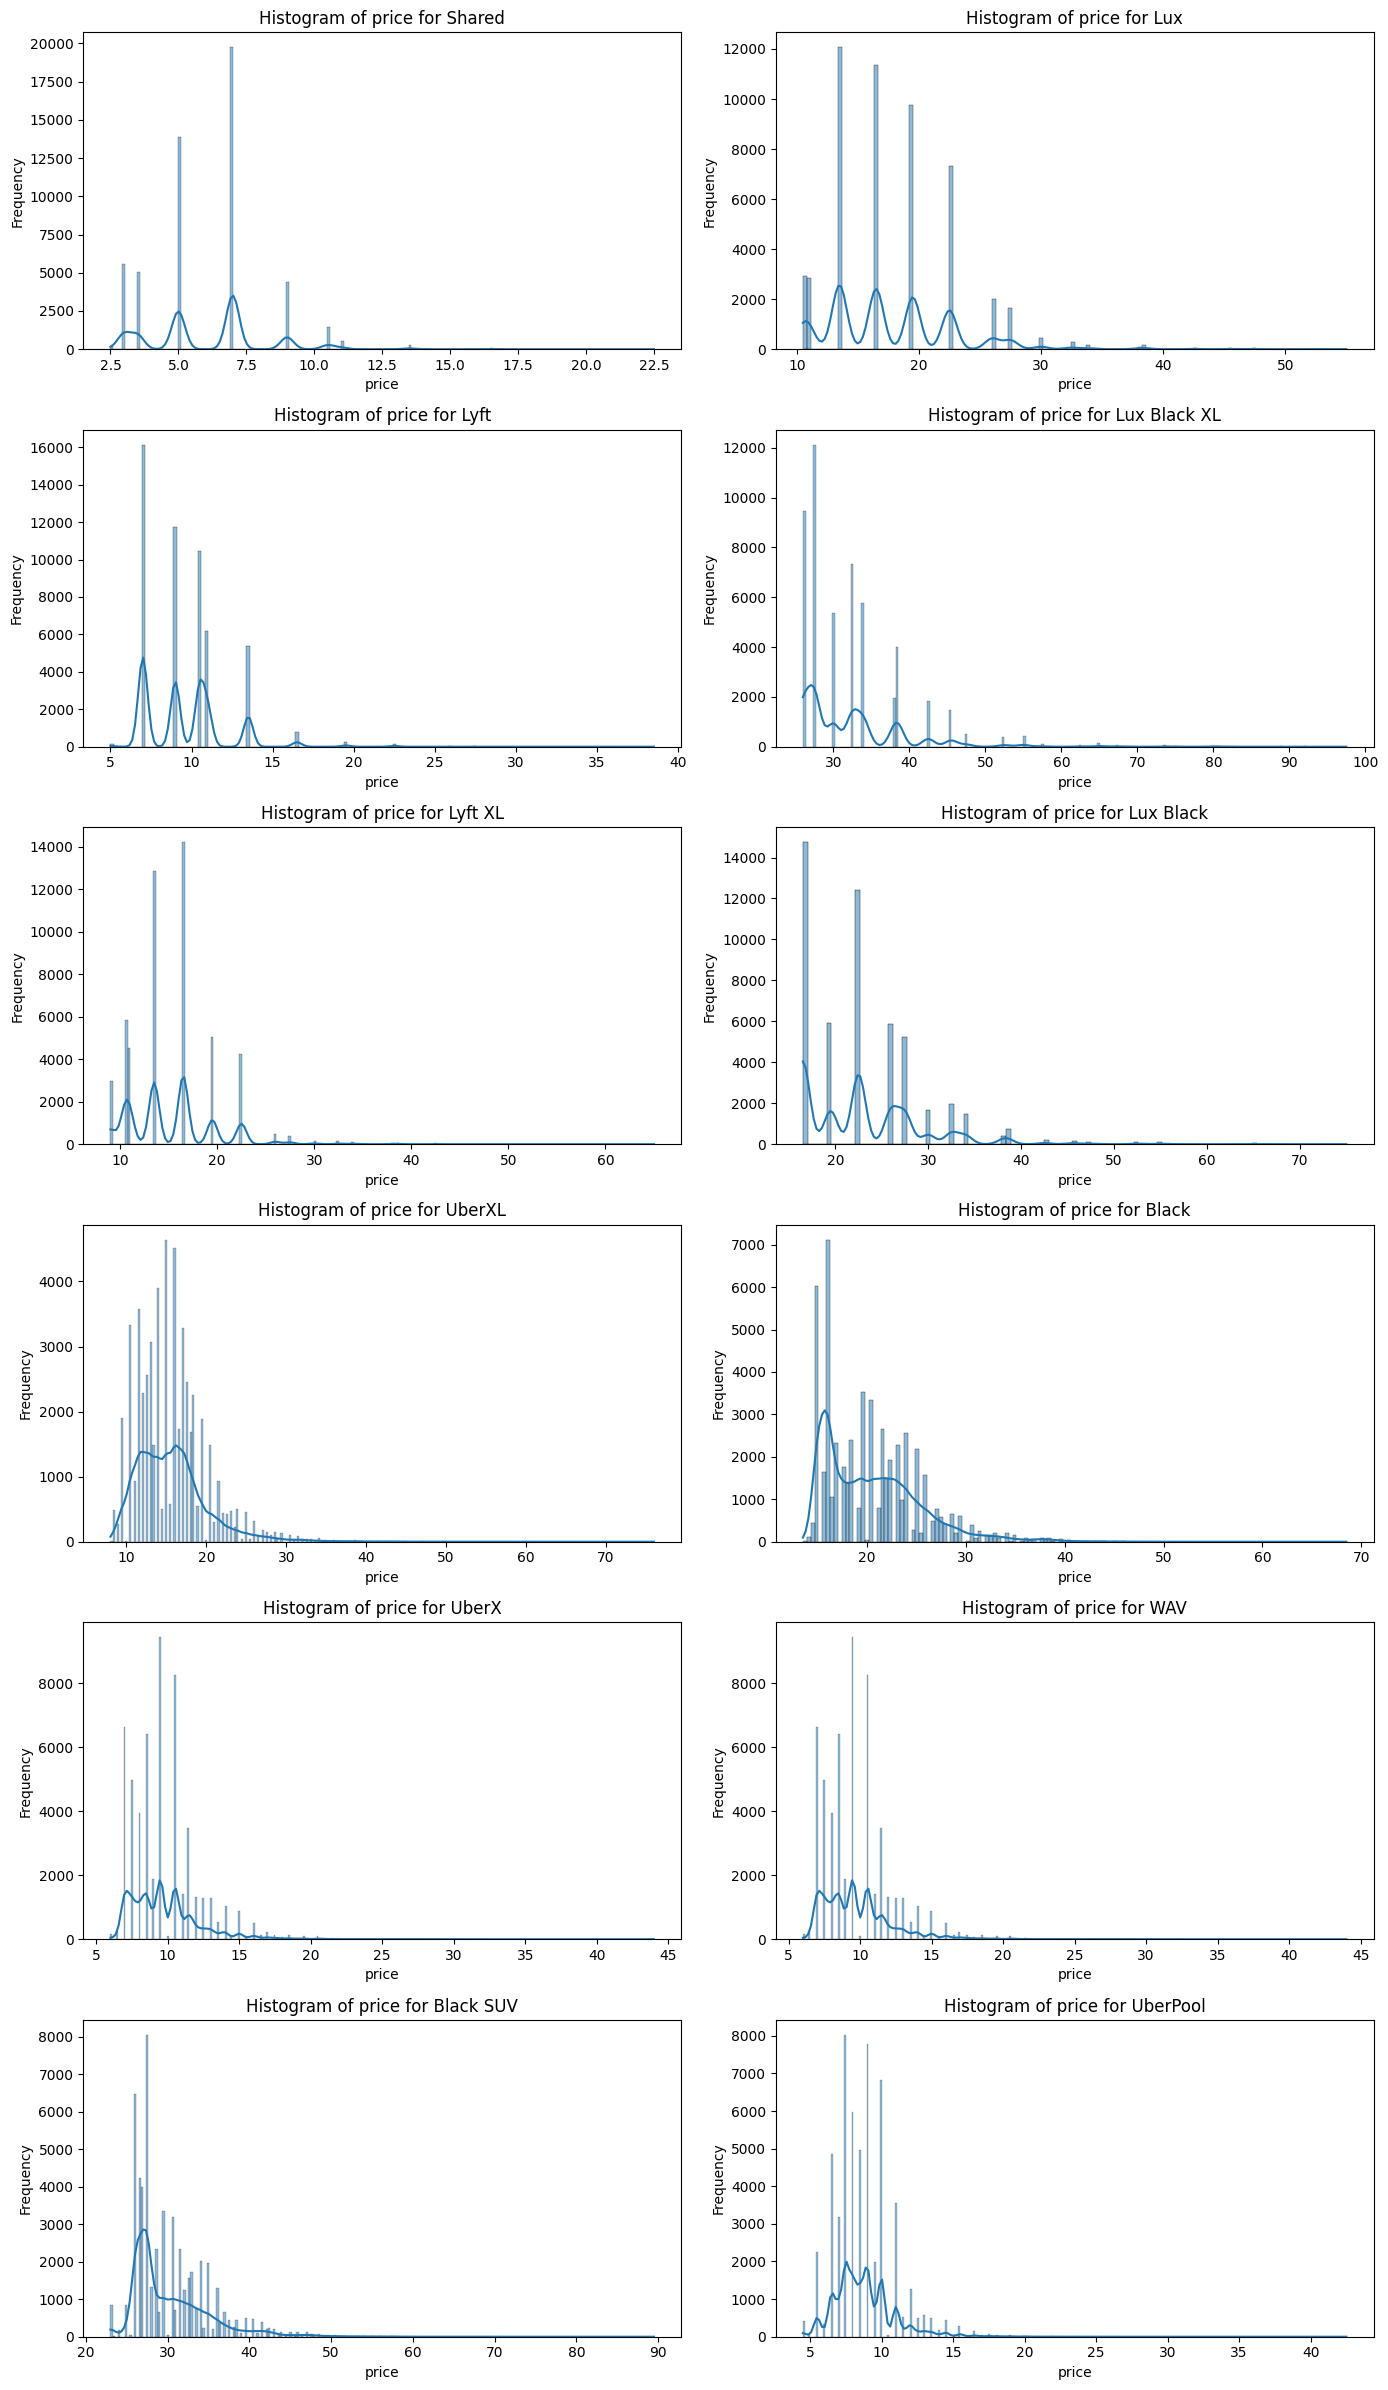

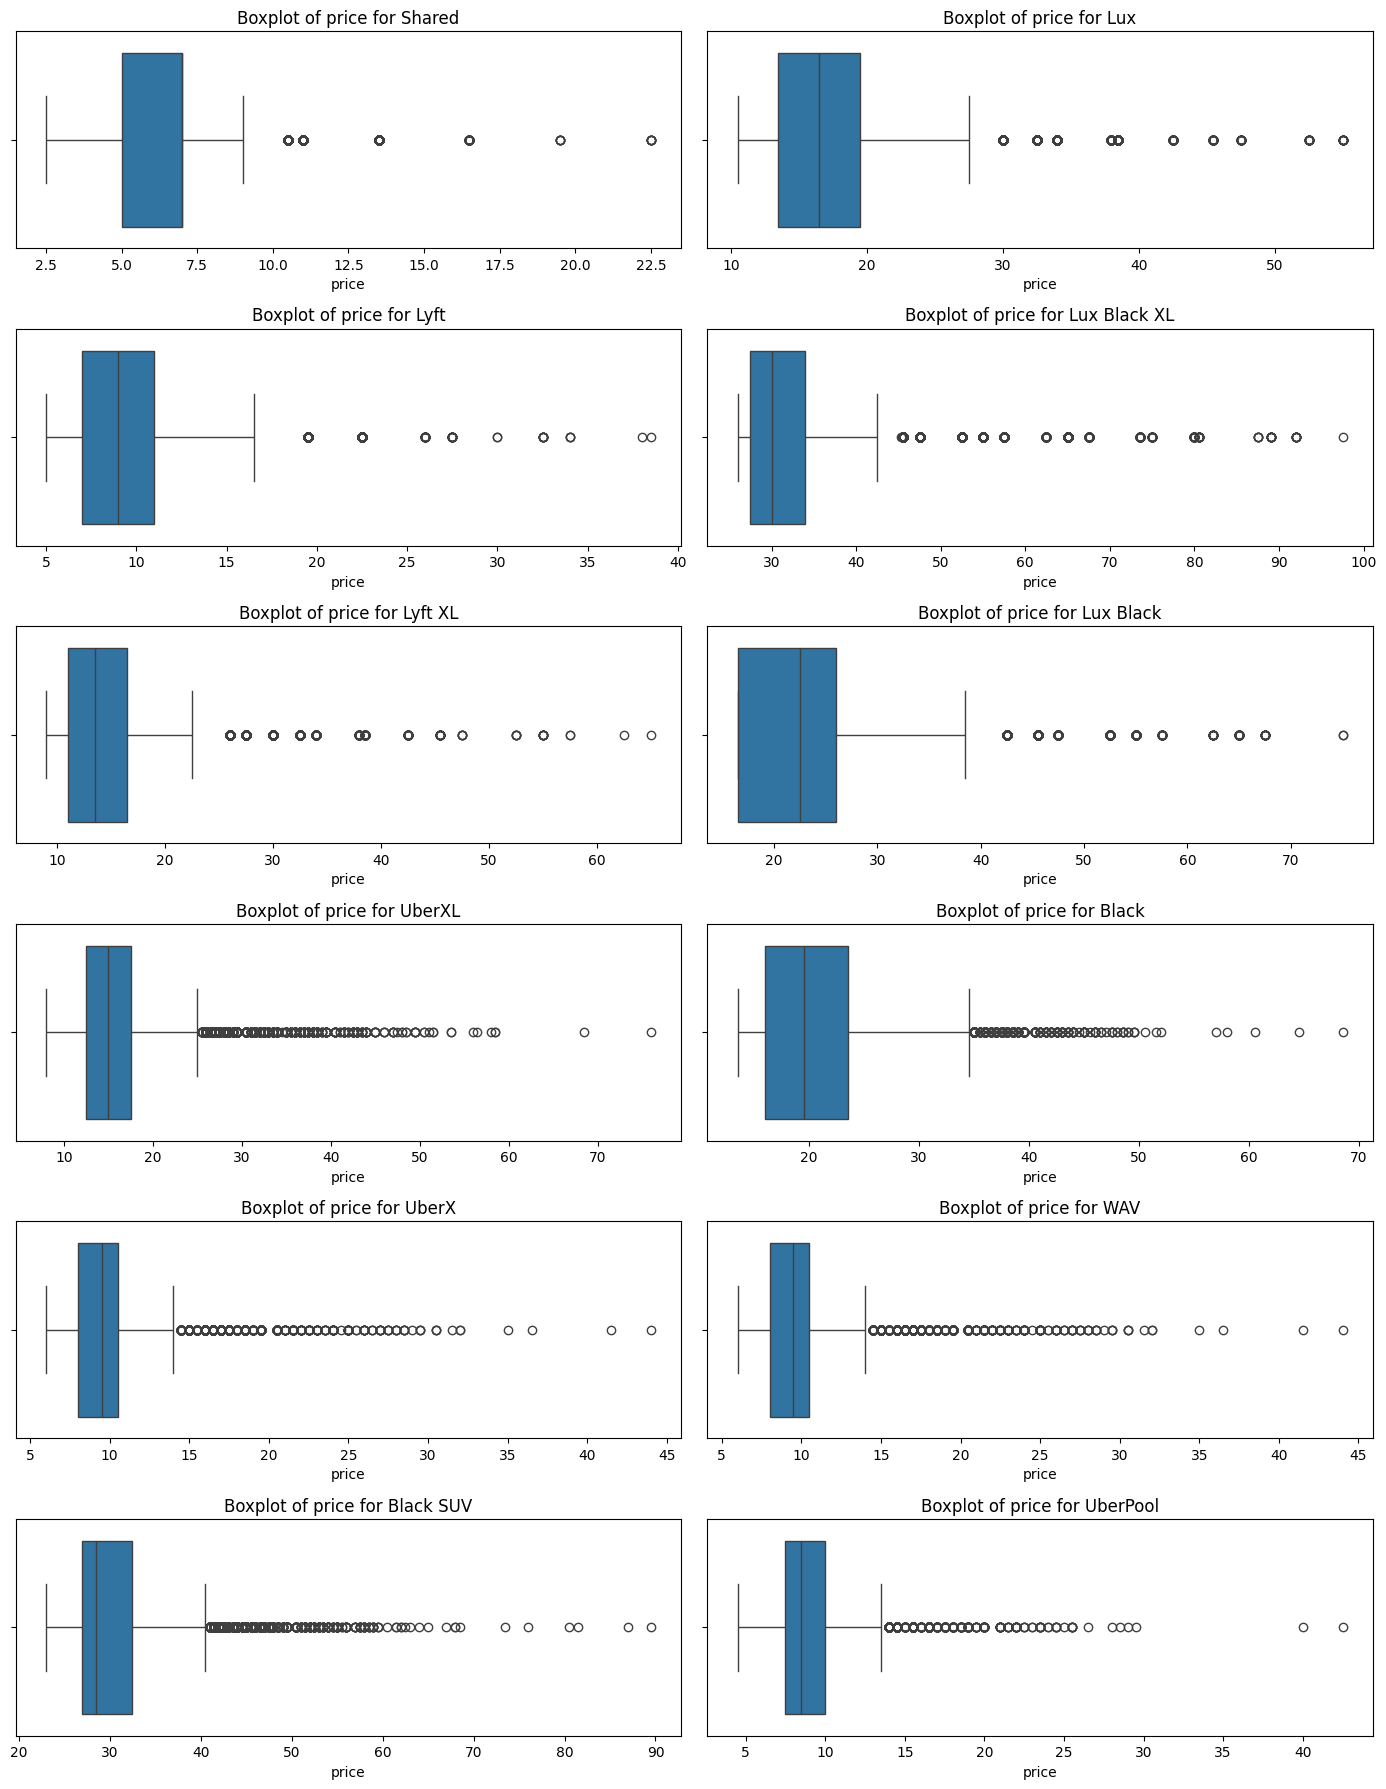

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


df_clean = df.copy()
df_clean["price"] = pd.to_numeric(df_clean["price"], errors="coerce")
df_clean = df_clean.dropna(subset=["price", "name"])

names = df_clean["name"].unique()


n = len(names)
ncols = 2
nrows = (n + 1) // ncols


plt.figure(figsize=(14, nrows*4))
for i, name in enumerate(names):
    temp = df_clean[df_clean["name"] == name]
    
    plt.subplot(nrows, ncols, i+1)
    sns.histplot(temp["price"], kde=True)
    plt.title(f"Histogram of price for {name}")
    plt.xlabel("price")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


plt.figure(figsize=(14, nrows*3))
for i, name in enumerate(names):
    temp = df_clean[df_clean["name"] == name]
    
    plt.subplot(nrows, ncols, i+1)
    sns.boxplot(x=temp["price"])
    plt.title(f"Boxplot of price for {name}")
    plt.xlabel("price")

plt.tight_layout()
plt.show()


The requested analyses were performed for all prices and then separately for each name. It can be observed that SUV, Black, and Uber XL have the highest number of outliers.

## 2_6

In [ ]:
from scipy.stats import shapiro

stat, p = shapiro(df['price'].dropna())
print('Statistics=%.3f, p=%.3f' % (stat, p))
if p > 0.05:
    print('Data looks normal')
else:
    print('Data does not look normal')


Statistics=0.912, p=0.000
Data does not look normal


C:\Users\asus\AppData\Roaming\Python\Python311\site-packages\scipy\stats\_axis_nan_policy.py:573: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 637976.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
from scipy.stats import kstest, norm


data = (df['price'].dropna() - df['price'].mean()) / df['price'].std()
stat, p = kstest(data, 'norm')
print('Statistics=%.3f, p=%.3f' % (stat, p))
if p > 0.05:
    print('Data looks normal')
else:
    print('Data does not look normal')


Statistics=0.132, p=0.000
Data does not look normal


Shapiro-Wilk Test: Statistics=0.912, p=0.000
Data does not look normal


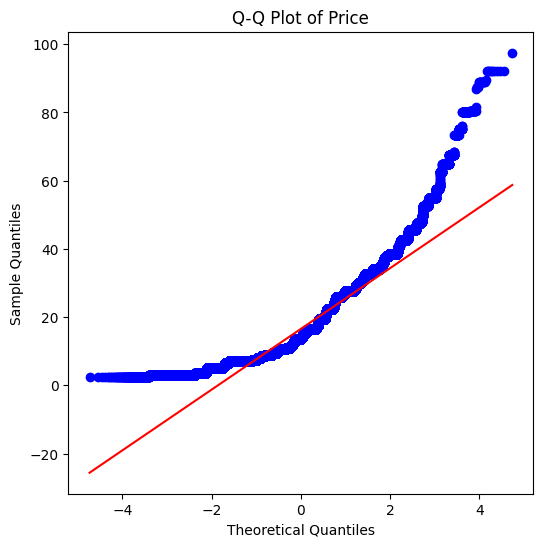

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats


data = df['price'].dropna()


stat, p = stats.shapiro(data)
print('Shapiro-Wilk Test: Statistics=%.3f, p=%.3f' % (stat, p))
if p > 0.05:
    print('Data looks normal')
else:
    print('Data does not look normal')


plt.figure(figsize=(6,6))
stats.probplot(data, dist="norm", plot=plt)
plt.title("Q-Q Plot of Price")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()


1_ Shapiro test
Null hypothesis (H0): The data follow a normal distribution.
Alternative hypothesis (H1): The data do not follow a normal distribution.
Advantages: High power for small sample sizes; provides accurate results.
Disadvantages: Very sensitive for very large sample sizes.
2_As a second method, we use the Q-Q Plot. Its advantages and disadvantages are as follows:
Advantages: Simple visual assessment; clearly shows skewness and outliers.
Disadvantages: Interpretation can be somewhat subjective; requires experience to judge normality accurately.


## 2_7

In [ ]:
import pandas as pd


df_clean = df.copy()


df_clean['price'] = pd.to_numeric(df_clean['price'], errors='coerce')
df_clean = df_clean.dropna(subset=['price', 'name'])


def remove_outliers_iqr(group):
    Q1 = group['price'].quantile(0.25)
    Q3 = group['price'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return group[(group['price'] >= lower_bound) & (group['price'] <= upper_bound)]


df_no_outliers_iqr = df_clean.groupby('name', group_keys=False).apply(remove_outliers_iqr)

print("Data count after removing outliers by IQR per name:", len(df_no_outliers_iqr))


Data count after removing outliers by IQR per name: 616311


C:\Users\asus\AppData\Local\Temp\ipykernel_15772\2157357926.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_no_outliers_iqr = df_clean.groupby('name', group_keys=False).apply(remove_outliers_iqr)


IQR Method

In [ ]:
import pandas as pd


df_clean = df.copy()


df_clean['price'] = pd.to_numeric(df_clean['price'], errors='coerce')
df_clean = df_clean.dropna(subset=['price', 'name'])


def remove_outliers_percentile(group, lower=0.01, upper=0.99):
    lower_bound = group['price'].quantile(lower)
    upper_bound = group['price'].quantile(upper)
    return group[(group['price'] >= lower_bound) & (group['price'] <= upper_bound)]


df_no_outliers_percentile = df_clean.groupby('name', group_keys=False).apply(remove_outliers_percentile)

print("Data count after removing outliers by Percentile per name:", len(df_no_outliers_percentile))


Data count after removing outliers by Percentile per name: 630192


C:\Users\asus\AppData\Local\Temp\ipykernel_15772\3249363211.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_no_outliers_percentile = df_clean.groupby('name', group_keys=False).apply(remove_outliers_percentile)


percentile method

The IQR method identifies outliers based on the statistical spread of the middle 50% of the data, making it sensitive to skewed or heavy-tailed distributions. In contrast, the percentile method removes a fixed percentage of the lowest and highest values, regardless of distribution shape. Overall, IQR is statistically meaningful but less flexible, while percentile clipping is more practical and fully controllable for data cleaning.

## 2_8

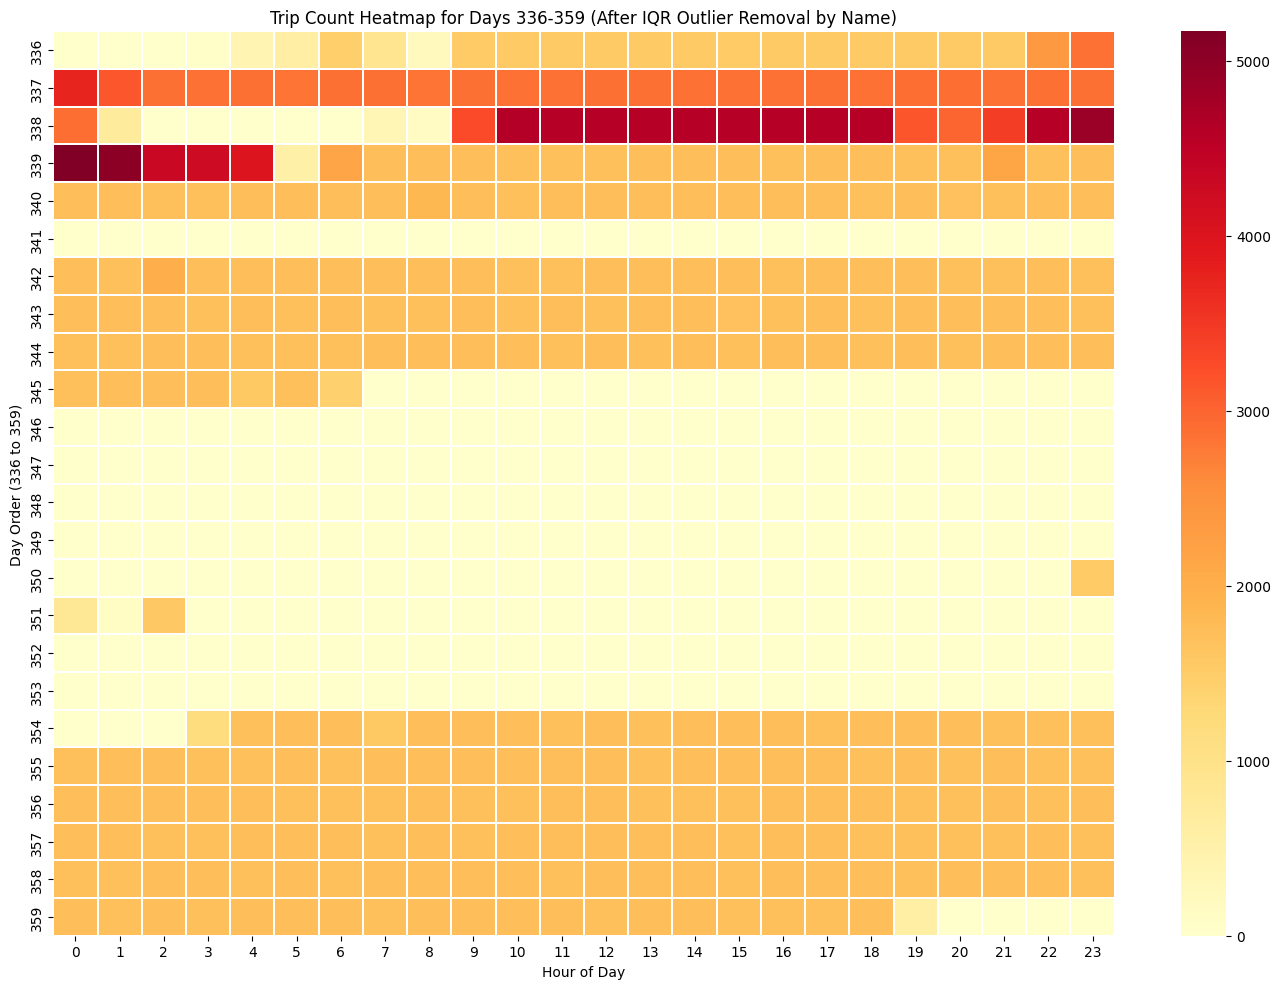

Total rows: 693071
Rows after removing outliers (by name): 636420
Removed rows: 56651
Percentage removed: 8.17%


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


cleaned_dfs = []

for n in df['name'].unique():
    df_name = df[df['name'] == n].copy()
    
    Q1 = df_name['price'].quantile(0.10)
    Q3 = df_name['price'].quantile(0.90)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df_name_clean = df_name[(df_name['price'] >= lower) & (df_name['price'] <= upper)].copy()
    
    cleaned_dfs.append(df_name_clean)


df_clean = pd.concat(cleaned_dfs, ignore_index=True)


df_clean['day_order'] = (df_clean['month'] - 1) * 31 + df_clean['day']


pivot_count = df_clean.pivot_table(
    index='day_order',
    columns='hour',
    values='price',
    aggfunc='count',
    fill_value=0
)


desired_days = np.arange(336, 360)  
all_hours = np.arange(0, 24)        

pivot_count = pivot_count.reindex(index=desired_days, columns=all_hours, fill_value=0)


plt.figure(figsize=(14,10))
sns.heatmap(pivot_count, cmap='YlOrRd', linewidths=0.3)
plt.title('Trip Count Heatmap for Days 336-359 (After IQR Outlier Removal by Name)')
plt.xlabel('Hour of Day')
plt.ylabel('Day Order (336 to 359)')
plt.tight_layout()
plt.show()


initial_rows = len(df)
final_rows = len(df_clean)
removed = initial_rows - final_rows
percent_removed = (removed / initial_rows) * 100

print("Total rows:", initial_rows)
print("Rows after removing outliers (by name):", final_rows)
print("Removed rows:", removed)
print("Percentage removed: %.2f%%" % percent_removed)


Using the IQR method, we remove outliers and take the 10th and 90th percentiles. We plot the first available data from day 336 to day 359. We observe that on days 337 to 339 the number of trips is very high, while on days 346 to 353 it is almost zero for some days.

Without plotting the heatmap, I expected the data to be scattered and only see a decrease in the number of trips at the end of each week, but this was not the case.

## 2_9

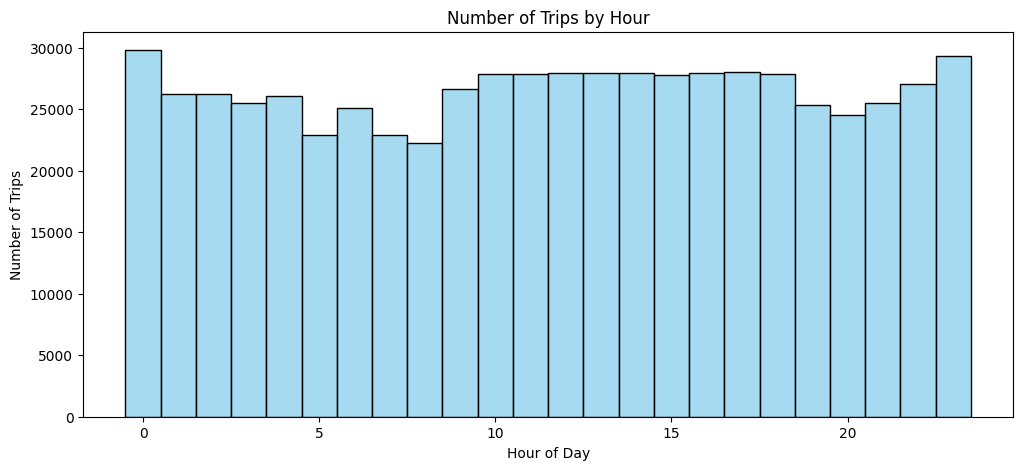

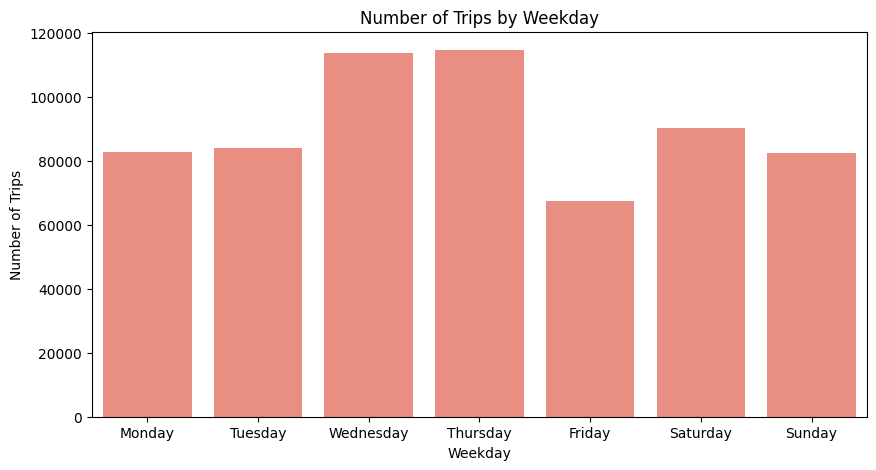

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns



df_clean['date'] = pd.to_datetime({
    'year': 2025,
    'month': df_clean['month'].astype(int),
    'day': df_clean['day'].astype(int)
})
df_clean['weekday'] = df_clean['date'].dt.day_name()


plt.figure(figsize=(12,5))
sns.histplot(df_clean, x='hour', bins=24, discrete=True, color='skyblue')
plt.title('Number of Trips by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.show()


plt.figure(figsize=(10,5))
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
sns.countplot(data=df_clean, x='weekday', order=order, color='salmon')
plt.title('Number of Trips by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Number of Trips')
plt.show()


According to the observations, between hours 10 and 20 the number of trips is usually similar, while one hour before 10 and after 20 there is a slight decrease, followed by an increase.
Regarding the weekdays, it is observed that the most trips occur on Wednesday and Thursday, while Friday has the fewest trips.

## 2_10

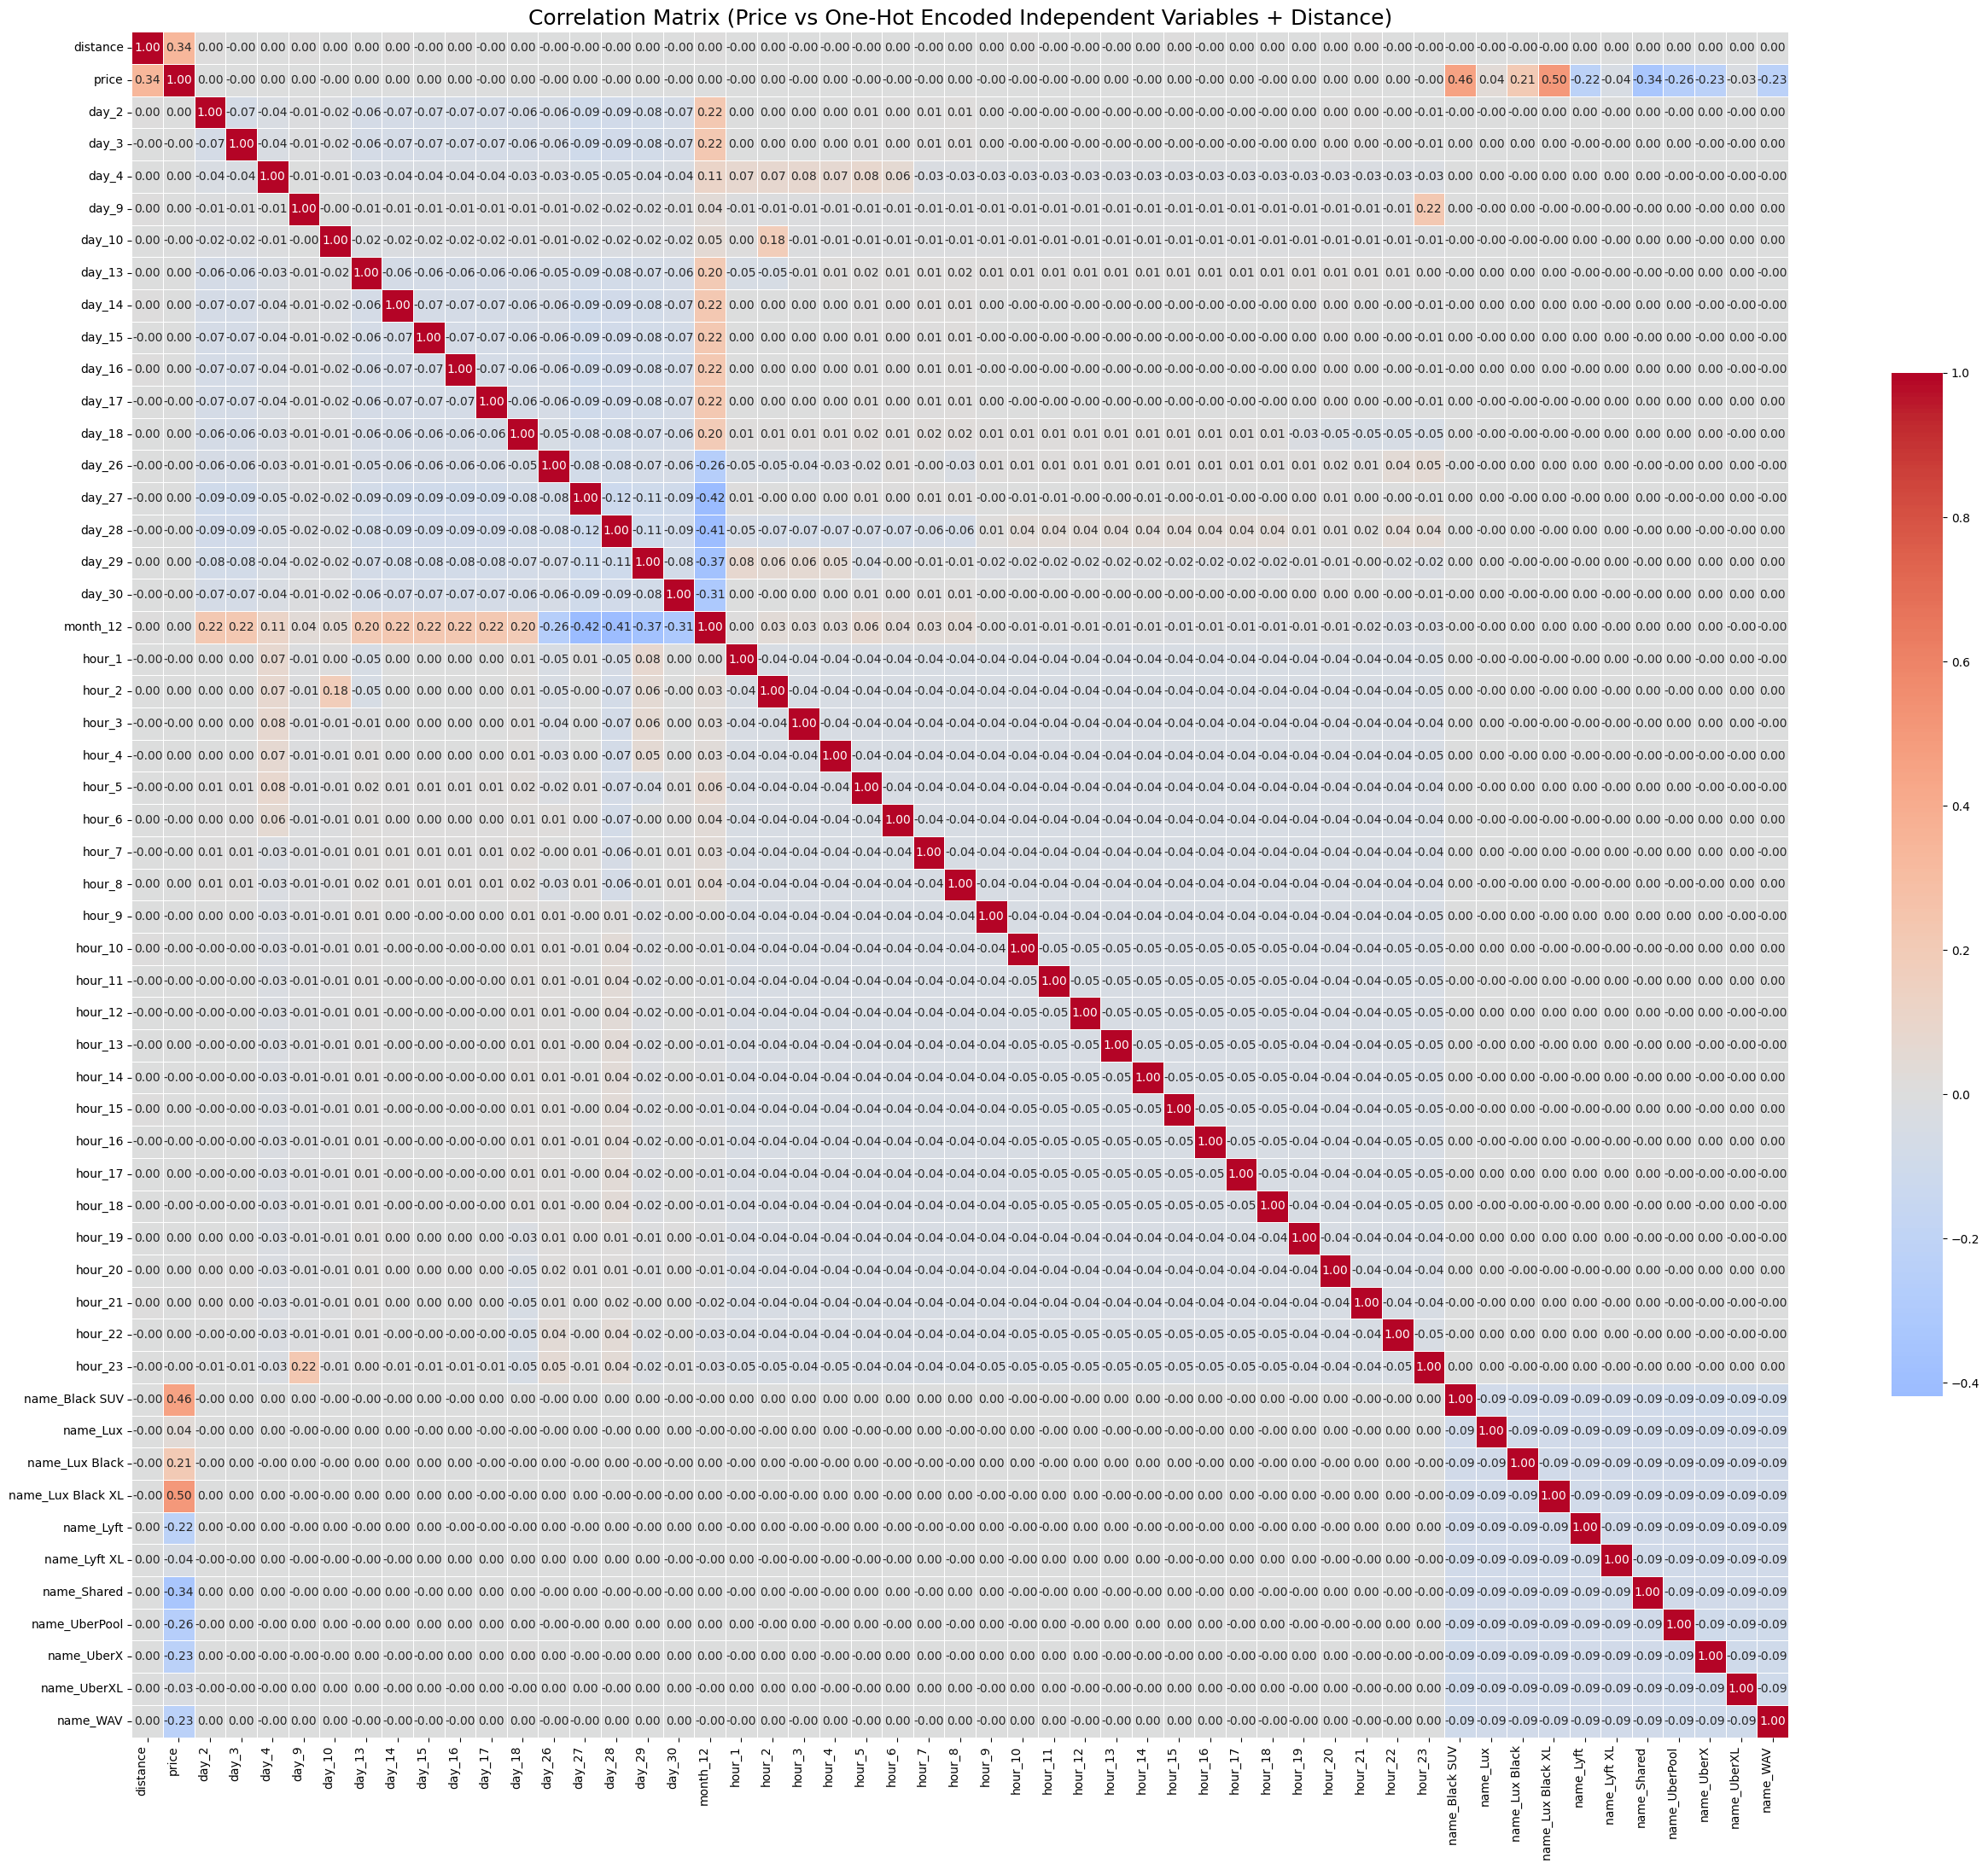

Correlation of features with price:
 price                1.000000
name_Lux Black XL    0.502665
name_Black SUV       0.459583
distance             0.338547
name_Lux Black       0.209420
name_Lux             0.038435
day_4                0.001662
day_9                0.001521
day_13               0.001510
day_27               0.001470
day_16               0.001449
hour_22              0.001343
hour_21              0.001292
day_15               0.001181
month_12             0.001141
hour_8               0.001095
hour_17              0.001009
hour_4               0.000970
day_29               0.000958
hour_19              0.000542
hour_20              0.000353
hour_13              0.000321
day_14               0.000307
day_18               0.000212
hour_2               0.000108
day_2                0.000084
hour_15              0.000023
day_26              -0.000059
hour_14             -0.000100
hour_5              -0.000188
hour_3              -0.000369
hour_9              -0.000390
hou

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


features = ['day', 'month', 'hour', 'name', 'distance', 'price']
df_subset = df_clean[features].copy()


df_dummies = pd.get_dummies(df_subset, columns=['day', 'month', 'hour', 'name'], drop_first=True)


corr_matrix = df_dummies.corr()


plt.figure(figsize=(26,22))
sns.heatmap(
    corr_matrix, 
    annot=True,      
    fmt=".2f",       
    cmap='coolwarm', 
    center=0, 
    linewidths=0.5,
    cbar_kws={"shrink":0.6}
)
plt.title('Correlation Matrix (Price vs One-Hot Encoded Independent Variables + Distance)', fontsize=18)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


price_corr = corr_matrix['price'].sort_values(ascending=False)
print("Correlation of features with price:\n", price_corr)


variables with a correlation greater than 0.30 show a moderate to strong relationship with price. These include name_Lux Black XL, name_Black SUV, and distance, indicating that these factors have the strongest positive influence on pricing.
Only one variable falls between 0.10 and 0.30, namely name_Lux Black, which shows a weak-to-moderate positive correlation with price.

## 3_1

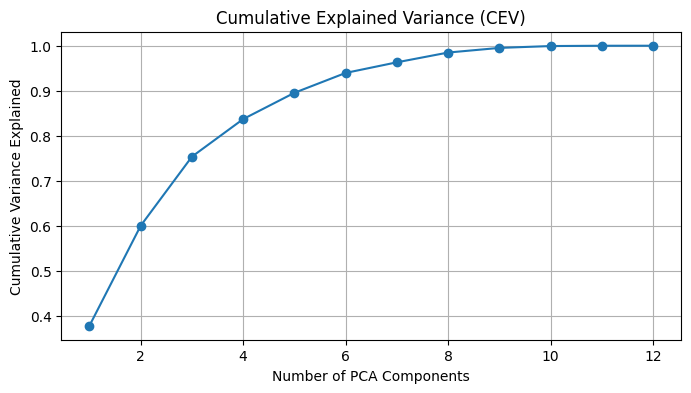

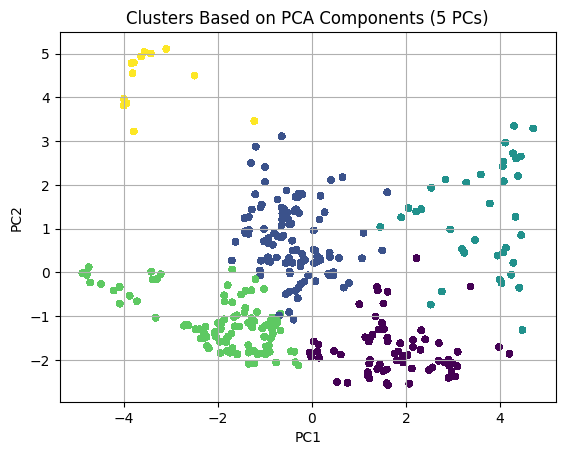

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt




weather_cols = [
    'temperature','apparentTemperature','humidity','windSpeed','windGust',
    'visibility','precipIntensity','precipProbability','pressure','dewPoint',
    'cloudCover','uvIndex'
]

weather = df[weather_cols].copy()
weather = weather.fillna(weather.mean())




scaler = StandardScaler()
weather_scaled = scaler.fit_transform(weather)




pca_test = PCA()
pca_test.fit(weather_scaled)

cev = np.cumsum(pca_test.explained_variance_ratio_)

plt.figure(figsize=(8,4))
plt.plot(range(1, len(cev)+1), cev, marker='o')
plt.title("Cumulative Explained Variance (CEV)")
plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Variance Explained")
plt.grid(True)
plt.show()




pca = PCA(n_components=5)
pca_components = pca.fit_transform(weather_scaled)


for i in range(5):
    df[f'weather_PC{i+1}'] = pca_components[:, i]




kmeans = KMeans(n_clusters=5, random_state=42)
df["weather_cluster"] = kmeans.fit_predict(pca_components)




plt.scatter(pca_components[:, 0], pca_components[:, 1], c=df["weather_cluster"], s=15)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters Based on PCA Components (5 PCs)")
plt.grid(True)
plt.show()


PCA can be used on weather data because many weather variables (temperature, humidity, wind, visibility, etc.) are highly correlated, and PCA reduces them into a few independent components that still capture most of the variation. The method used here first standardizes all weather features, then creates a Cumulative Explained Variance (CEV) plot to choose the optimal number of components. After selecting the top components, PCA compresses the weather information into a smaller set of meaningful features. These new PCA components can then be used in prediction models or clustering to improve accuracy and reduce noise.

## 3_2&3

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report




df_copy = df.copy()




df_copy['Rain'] = (df_copy['precipIntensity'] > 0).astype(int)




weather_cols = [
    'temperature', 'apparentTemperature', 'humidity', 'windSpeed',
    'windGust', 'pressure', 'cloudCover', 'ozone', 'dewPoint'
]

X = df_copy[weather_cols]
y = df_copy['Rain']




X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)




log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=200))
])

log_reg_pipeline.fit(X_train, y_train)
y_pred_lr = log_reg_pipeline.predict(X_test)

print("==== Logistic Regression ====")
print(classification_report(y_test, y_pred_lr))




svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearSVC(
        C=0.5,        
        max_iter=3000,
        random_state=42
    ))
])

svm_pipeline.fit(X_train, y_train)
y_pred_svm = svm_pipeline.predict(X_test)

print("==== Linear SVM  ====")
print(classification_report(y_test, y_pred_svm))


==== Logistic Regression ====
              precision    recall  f1-score   support

           0       0.96      0.95      0.95    108449
           1       0.83      0.84      0.83     30166

    accuracy                           0.93    138615
   macro avg       0.89      0.90      0.89    138615
weighted avg       0.93      0.93      0.93    138615

==== Linear SVM  ====
              precision    recall  f1-score   support

           0       0.95      0.95      0.95    108449
           1       0.82      0.83      0.83     30166

    accuracy                           0.92    138615
   macro avg       0.89      0.89      0.89    138615
weighted avg       0.92      0.92      0.92    138615



Logistic Regression models the probability of rain using a linear decision boundary and works well when the relationship between features and the target is mostly linear.
Linear SVM finds the best separating hyperplane with maximum margin, making it effective for high-dimensional, linearly separable data.
Both models performed well, but Logistic Regression achieved slightly higher accuracy, precision, and recall for predicting rain.
The SVM model was stable and avoided overfitting, but its performance was marginally lower on the minority class (rain).
Therefore, Logistic Regression is the better model because it provides a more balanced and accurate classification for both classes.

## Statistical analysis



## Developing models to predict price

### Prework
Because we want to make a regression model, we should make columns numeric, by encoding, and we do these: drop ID's, drop summary, make cab-type dummy and make origin destination pair and then make that dummy(this is cancelled because of high number of columns it makes, so we make source and destination dummy).



In [16]:
RideDataForRegression = RideData.copy()
# 1) Make cab_type dummies
RideDataForRegression = pd.get_dummies(RideDataForRegression, columns=['cab_type'], prefix='cab', dtype=int, drop_first=True)

# 2) Create origin–destination pair
#RideDataForRegression['origin_dest'] = RideDataForRegression['source'] + "_" + RideDataForRegression['destination']

# 3) Make dummies for origin–destination
#RideDataForRegression = pd.get_dummies(RideDataForRegression, columns=['origin_dest'], prefix='od', dtype=int, drop_first=True)

# 4) remove the original columns

RideDataForRegression = pd.get_dummies(RideDataForRegression, columns=['source'], prefix='src', dtype=int, drop_first=True)
RideDataForRegression = pd.get_dummies(RideDataForRegression, columns=['destination'], prefix='od', dtype=int, drop_first=True)


In [17]:
RideDataForRegression = RideDataForRegression.drop(columns=[ 'id', 'product_id', 'short_summary','long_summary'])


In [19]:
RideDataForRegression.info()

<class 'pandas.core.frame.DataFrame'>
Index: 637976 entries, 0 to 693070
Data columns (total 65 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   hour                         637976 non-null  int64  
 1   day                          637976 non-null  int64  
 2   month                        637976 non-null  int64  
 3   price                        637976 non-null  float64
 4   distance                     637976 non-null  float64
 5   surge_multiplier             637976 non-null  float64
 6   latitude                     637976 non-null  float64
 7   longitude                    637976 non-null  float64
 8   temperature                  637976 non-null  float64
 9   apparentTemperature          637976 non-null  float64
 10  precipIntensity              637976 non-null  float64
 11  precipProbability            637976 non-null  float64
 12  humidity                     637976 non-null  float64
 13  wind



### Feature selection:
First we want to find best columns to be used in model.

#### Using backward elimination

Backward elimination starts with the full set of predictors and progressively removes the least useful ones by checking how their removal affects the model’s R². 
However, backward elimination is computationally heavier, especially with many dummy variables. Overall, in linear regression, backward elimination is thorough and captures combined effects but can be slow and sensitive to correlated features.

We removed a source and destination dummy columns, because they made a lot of columns making backward elimination impossible to execute on this PC, plus we used a part of data(20 percent randomly) for the same reason.


In [22]:
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
import numpy as np


In [23]:

#### Using Backward elimination
X = RideDataForRegression.drop(columns=['price'] + [c for c in RideDataForRegression.columns if c.startswith(('src_', 'od_'))])
y = RideDataForRegression['price']
#just to use less data
X, X_, y, y_ = train_test_split(X, y, test_size=0.8, random_state=42)

def fast_backward_elimination(X, y):
    features = list(X.columns)
    
    # compute initial score with all features
    model = LinearRegression()
    best_score = cross_val_score(model, X[features], y, cv=5, scoring='r2').mean()

    improved = True
    while improved and len(features) > 1:
        scores = {}

        # try removing each feature
        for col in features:
            temp = [f for f in features if f != col]
            model = LinearRegression()
            r2 = cross_val_score(model, X[temp], y, cv=5, scoring='r2').mean()
            scores[col] = r2

        # find which removal gives the highest R2
        worst_feature = max(scores, key=scores.get)
        worst_r2 = scores[worst_feature]

        # if removing this feature improves or keeps R2, drop it
        if worst_r2 >= best_score:
            features.remove(worst_feature)
            best_score = worst_r2
        else:
            improved = False

    return features, best_score

selected_features_backward, final_r2 = fast_backward_elimination(X, y)

print("Remaining features:", selected_features_backward)
print("Final R²:", final_r2)


Remaining features: ['hour', 'distance', 'surge_multiplier', 'latitude', 'humidity', 'visibility', 'temperatureHigh', 'apparentTemperatureHigh', 'dewPoint', 'windBearing', 'uvIndex', 'ozone', 'temperatureMax', 'apparentTemperatureMax', 'name_Black SUV', 'name_Lux Black', 'name_Lux Black XL', 'name_Lyft', 'name_Lyft XL', 'name_Shared', 'name_UberPool', 'name_UberX', 'name_UberXL', 'name_WAV', 'cab_Uber']
Final R²: 0.9255116082252158




#### Using Forward selection
Forward selection begins with no predictors and adds variables one by one based on which inclusion gives the largest improvement in the model’s R². This method is useful because it builds a regression model where every selected variable demonstrably adds unique linear explanatory power and avoids overfitting by refusing to add features that don’t improve performance. However, forward selection can miss variables whose usefulness only appears when combined with others. In short, for linear regression, forward selection provides a compact, interpretable model but may fail to capture interactions and hidden structure.

Here we removed a source and destination dummy columns, because they made a lot of columns making forward selection impossible to execute on this PC, plus we used a part of data(20 percent randomly) for the same reason.

In [ ]:

X = RideDataForRegression.drop(columns=['price'] + [c for c in RideDataForRegression.columns if c.startswith(('src_', 'od_'))])
y = RideDataForRegression['price']
#just to use less data
X, X_, y, y_ = train_test_split(X, y, test_size=0.8, random_state=42)

def fast_forward_selection(X, y):
    remaining = list(X.columns)
    selected = []
    best_score = -np.inf

    while remaining:
        scores = {}

        for col in remaining:
            model = LinearRegression()
            cols_to_try = selected + [col]
            # 5-fold cross-validated R2 (fast, stable)
            r2 = cross_val_score(model, X[cols_to_try], y, cv=5, scoring='r2').mean()
            scores[col] = r2

        # pick best feature
        best_feature = max(scores, key=scores.get)
        best_feature_score = scores[best_feature]

        if best_feature_score > best_score:
            selected.append(best_feature)
            best_score = best_feature_score
            remaining.remove(best_feature)
        else:
            break

    return selected, best_score

selected_features_forward, best_r2 = fast_forward_selection(X, y)

print("Selected features:", selected_features_forward)
print("Best R2:", best_r2)



Selected features: ['name_Lux Black XL', 'name_Black SUV', 'distance', 'name_Lux Black', 'name_Shared', 'surge_multiplier', 'name_UberPool', 'name_Lyft', 'name_UberX', 'name_WAV', 'name_Lyft XL', 'name_UberXL', 'name_Lux', 'temperature', 'windBearing', 'latitude', 'uvIndex', 'hour', 'temperatureLow', 'apparentTemperatureLow']
Best R2: 0.9255117308242788


#### Using correlation matrix

Easiest way to find good columns to be used in linear regression is finding columns with high colinearity with target, code below finds columns with colinearity value more than 0.2.

pros are that we can select features as fast as possible, cons are that we dont know the impacts of these features on R2 and accuracy because we did not select them to make higher accuracy, we selected them because they had higher colinearity with target and we are not sure that model will have a good R2, and also can mislead you: a variable might look weak individually but become powerful in combination.

In [ ]:
# correlations with price, sorted
corr_price = RideDataForRegression.corr()['price'].drop('price').sort_values(ascending=False)
corr_price_sorted = corr_price.reindex(corr_price.abs().sort_values(ascending=False).index)
selected_featuress_corr = corr_price_sorted[abs(corr_price_sorted) > 0.2]
print(selected_featuress_corr)


name_Lux Black XL    0.500057
name_Black SUV       0.453096
distance             0.345061
name_Shared         -0.333235
name_UberPool       -0.256930
surge_multiplier     0.240458
name_WAV            -0.223557
name_UberX          -0.223551
name_Lyft           -0.219756
name_Lux Black       0.206544
Name: price, dtype: float64


In [ ]:
selected_featuress_corr.keys()

Index(['name_Lux Black XL', 'name_Black SUV', 'distance', 'name_Shared',
       'name_UberPool', 'surge_multiplier', 'name_WAV', 'name_UberX',
       'name_Lyft', 'name_Lux Black'],
      dtype='object')

### Making regression model

Here we make three regression models using features we selected with three techniques:

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# ------------------------------------------
# X and y
# ------------------------------------------
# Example:
X_corr = RideDataForRegression[selected_featuress_corr.keys()]
X_forward = RideDataForRegression[selected_features_forward]
X_backward = RideDataForRegression[selected_features_backward]
y = RideDataForRegression['price']

# ------------------------------------------
# Train/Test Split
# ------------------------------------------
X_train_corr, X_test_corr, y_train_corr, y_test_corr = train_test_split(
    X_corr, y, test_size=0.2, random_state=42
)
X_train_forward, X_test_forward, y_train_forward, y_test_forward = train_test_split(
    X_forward, y, test_size=0.2, random_state=42
)
X_train_backward, X_test_backward, y_train_backward, y_test_backward = train_test_split(
    X_backward, y, test_size=0.2, random_state=42
)

# ------------------------------------------
# Optional: Scaliing
# ------------------------------------------
scaler = StandardScaler()

X_train_corr_scaled = scaler.fit_transform(X_train_corr)
X_test_corr_scaled = scaler.transform(X_test_corr)
X_train_forward_scaled = scaler.fit_transform(X_train_forward)
X_test_forward_scaled = scaler.transform(X_test_forward)
X_train_backward_scaled = scaler.fit_transform(X_train_backward)
X_test_backward_scaled = scaler.transform(X_test_backward)

# ------------------------------------------
# Fit Linear Regression
# ------------------------------------------
def create_model__and_display(X_train_scaled, y_train , X_test, X_test_scaled,y_test, tech =""):
    model = LinearRegression()


    model.fit(X_train_scaled, y_train)

    # ------------------------------------------
    # Prediction
    # ------------------------------------------
    y_pred = model.predict(X_test_scaled)

    # ------------------------------------------
    # Metrics
    # ------------------------------------------
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)

    # Adjusted R²
    n = X_test.shape[0]
    p = X_test.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    print(f'Technique used:{tech}---')
    print("R²:", r2)
    print("Adjusted R²:", adj_r2)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("MAE:", mae)
    print("-----------------")
create_model__and_display(X_train_corr_scaled, y_train_corr , X_test_corr, X_test_corr_scaled,y_test_corr, tech="Correlation-based Selection")
create_model__and_display(X_train_forward_scaled, y_train_forward , X_test_forward, X_test_forward_scaled,y_test_forward, tech="Forward Selection")
create_model__and_display(X_train_backward_scaled, y_train_backward , X_test_backward, X_test_backward_scaled,y_test_backward, tech="Backward Selection")

Technique used:Correlation-based Selection---
R²: 0.9080020011359662
Adjusted R²: 0.9079947904137916
MSE: 8.02042441916317
RMSE: 2.832035384518204
MAE: 2.089752188817383
-----------------
Technique used:Forward Selection---
R²: 0.9273914205159193
Adjusted R²: 0.9273800376306386
MSE: 6.330046643683446
RMSE: 2.5159583946646347
MAE: 1.776988216466947
-----------------
Technique used:Backward Selection---
R²: 0.927388122826306
Adjusted R²: 0.9273738930157758
MSE: 6.33033413765753
RMSE: 2.51601552810342
MAE: 1.777017103715332
-----------------


#### Evaluating models:

if we consider R2, model1 has less R2 than others, if we consider MSE as a perfoormance indicator, again model1 performes worse, so the model1 eliminated.
model2 and model3 performe equally, but model2 performs slightly better, but if we consider number of features, model3 uses 20 features and model3 use 25, because the performance are the same we know that model3 uses features that don't give us enough information and are useless, so we select model3(Forward selection) because of less features it uses.

### XG-boost and RandomForest

#### Random forest

We remove $source$ and $destination$ dummies to make $RandomForest$ be made faster, the RandomForest is made with 100 trees and depth of trees are unlimited for this part.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

X = RideDataForRegression.drop(columns=['price']+ [c for c in RideDataForRegression.columns if c.startswith(('src_', 'od_'))])
y = RideDataForRegression['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(
    n_estimators=100,      # number of trees
    max_depth=None,        # grow trees to full depth
    random_state=42,
    n_jobs=-1              # use all CPU cores
)
rf.fit(X_train, y_train)

y_pred_train = rf.predict(X_train)
y_pred_test = rf.predict(X_test)

mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)
mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

print("=== Random Forest ===")
print(f'Test MSE: {mse_test}')
print(f'Test R2: {r2_test}')
print(f'Train MSE: {mse_train}')
print(f'Train R2: {r2_train}')

====Random Forest====
Test MSE: 3.7968989993430897
Test R2: 0.9564478023140748
Train MSE: 1.149866456117089
Train R2: 0.986765543830061


#### XG-boost
Code below makes an XG-boost model, we can use source and destination dummies here because model is made faster comparing to RandomForest.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

# -------------------------------
# Train/Test Split
# -------------------------------
X = RideDataForRegression.drop('price', axis=1)  
y = RideDataForRegression['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# -------------------------------
#  XGBoost Model
# -------------------------------
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb.fit(X_train, y_train)

xgb_pred_train = xgb.predict(X_train)
xgb_pred_test = xgb.predict(X_test)


xgb_r2_test = r2_score(y_test, xgb_pred_test)
xgb_mse_test = mean_squared_error(y_test, xgb_pred_test)
xgb_rmse_test = np.sqrt(xgb_mse_test)
xgb_r2_train = r2_score(y_train, xgb_pred_train)
xgb_mse_train = mean_squared_error(y_train, xgb_pred_train)
xgb_rmse_train = np.sqrt(xgb_mse_train)

print("\n=== XGBoost ===")
print("R²:", xgb_r2_test)
print("MSE:", xgb_mse_test)
print("RMSE:", xgb_rmse_test)
print("R² (Train):", xgb_r2_train)
print("MSE (Train):", xgb_mse_train) 
print("RMSE (Train):", xgb_rmse_train)




=== XGBoost ===
R²: 0.9691972047819954
MSE: 2.6854007043141204
RMSE: 1.6387192268091932
R² (Train): 0.9709841459217017
MSE (Train): 2.521022161530737
RMSE (Train): 1.587772704618245


### Models Comparison

We made three linear regression models(we chose best model), a RandomForest and an XG-boost model.

results are: 

=== XGBoost ===

R²: 0.9691972047819954

MSE: 2.6854007043141204

RMSE: 1.6387192268091932

R² (Train): 0.9709841459217017

MSE (Train): 2.521022161530737

RMSE (Train): 1.587772704618245

====Random Forest====

Test MSE: 3.7968989993430897

Test R2: 0.9564478023140748

Train MSE: 1.149866456117089

Train R2: 0.986765543830061

=== LinearRegression ===

R²: 0.927388122826306

Adjusted R²: 0.9273738930157758

MSE: 6.33033413765753

RMSE: 2.51601552810342

MAE: 1.777017103715332



The linear regression model has less R2 and worse MSE, so it is eliminated. XG-boost and RandomForest have close R2, but MSE for XG-boost is lower, and also XG-boost R2 and MSE are so close in train and test showing that the model is not overfitted, something we don't see in RandomForest because RandomForest is performing much better in train accuracy showing it is overfitted, so the selected model is $XGBoost$ 

### Finding best parameters

we can use GridSearch or taguchi, GridSearch examines full GridSpace but taguchi finds approximate best parameters and does not search full space, because it takes a lot to generate models, GridSearch takes so much time making models with all combinations, so we can use a part of data or use taguchi(if we use both searchs, taguchi will be redundant).


We use 20 percent of data to train and test the models.

In [ ]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import time

X = RideDataForRegression.drop(columns=['price']+ [c for c in RideDataForRegression.columns if c.startswith(('src_', 'od_'))])
y = RideDataForRegression['price']

X, X_, y, y_ = train_test_split(X, y, test_size=0.8, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# --- Grid Search ---
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

rf = RandomForestRegressor(random_state=42, n_jobs=-1)
start = time.time()
grid_search = GridSearchCV(rf, param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
grid_search.fit(X_train, y_train)
end = time.time()

best_rf_grid = grid_search.best_estimator_
y_pred_grid = best_rf_grid.predict(X_test)
mse_grid = mean_squared_error(y_test, y_pred_grid)

print(f"Grid Search MSE: {mse_grid:.3f}, Time: {end-start:.2f}s")
print(f"Best params: {grid_search.best_params_}")


Grid Search MSE: 3.682, Time: 432.87s
Best params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}


For XG-boost we use 40 percent of data.

In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

# --- Load dataset ---
X = RideDataForRegression.drop(columns=['price'])
y = RideDataForRegression['price']
X, X_, y, y_ = train_test_split(X, y, test_size=0.6, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# --- Define hyperparameter grid ---
param_grid = {
    "n_estimators": [100, 200, 500],
    "max_depth": [3, 5, 10],
    "learning_rate": [0.02, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

# --- Initialize XGBoost Regressor ---
xgb = XGBRegressor(random_state=42, n_jobs=-1)

# --- Grid Search ---
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

# --- Evaluate ---
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

print(f"Best Params: {grid_search.best_params_}")
print(f"Test MSE: {mse:.3f}")


Fitting 3 folds for each of 162 candidates, totalling 486 fits
Best Params: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 500, 'subsample': 1.0}
Test MSE: 2.875


For RandomForest we found a better model despite using a small part of data, but for the XG-boost the best model performes worse than previous XG-boost model, there are two reasons, one is that data we use is 40 percent of data, and other is that we used other parameters(for example max depth was 6 in first XG-boost model and now candidas are 3,5 and 10)
but best model performance here is close to first XG-boost model.

In [ ]:
from sklearn.metrics import r2_score,mean_squared_error
pred=  best_model.predict(X_)
mse = mean_squared_error(y_,pred)
r2=r2_score(y_,pred)
mse,r2

(2.7841543276039604, 0.9679750082269075)

We see that the best model(parameters found using GridSearch) performs better on a bigger test data, if we train it with bigger data it will perform better:

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

# -------------------------------
# Train/Test Split
# -------------------------------
X = RideDataForRegression.drop('price', axis=1)  
y = RideDataForRegression['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
#  XGBoost Model
# -------------------------------
xgb = XGBRegressor(
colsample_bytree=0.8,learning_rate= 0.1,max_depth= 5, n_estimators= 500,subsample= 1.0
)

xgb.fit(X_train, y_train)

xgb_pred_train = xgb.predict(X_train)
xgb_pred_test = xgb.predict(X_test)


xgb_r2_test = r2_score(y_test, xgb_pred_test)
xgb_mse_test = mean_squared_error(y_test, xgb_pred_test)
xgb_rmse_test = np.sqrt(xgb_mse_test)
xgb_r2_train = r2_score(y_train, xgb_pred_train)
xgb_mse_train = mean_squared_error(y_train, xgb_pred_train)
xgb_rmse_train = np.sqrt(xgb_mse_train)

print("\n=== XGBoost ===")
print("R²:", xgb_r2_test)
print("MSE:", xgb_mse_test)
print("RMSE:", xgb_rmse_test)
print("R² (Train):", xgb_r2_train)
print("MSE (Train):", xgb_mse_train) 
print("RMSE (Train):", xgb_rmse_train)





=== XGBoost ===
R²: 0.9684784797836522
MSE: 2.7480594534016367
RMSE: 1.6577271951083015
R² (Train): 0.9689114680361239
MSE (Train): 2.701105328104291
RMSE (Train): 1.6435039787308976


Slightly better performance but not better than first XG-boost model(because we did not test enough parameters)

### Combining Models
Here we combine models to make a better model,
but because of memory problems accuring during model making, we use a part of data instead od whole data, but to make sure model is performing better, we test the models before combining and after.

#### Boosted Forest
Now we want to make predicitions using more than one model, first model we make is based on research  $Boosting Random Forests to Reduce Bias; One-Step Boosted Forest and its Variance Estimate
$
(paper on link https://arxiv.org/pdf/1803.08000)


For the first model we do a hybrid approach where best RandomForest we found is the “main” model (predicting price) and then we use RandomForestRegressor (RF) to predict the residuals.

In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Assume df cleaned and X, y defined
X = RideDataForRegression.drop(columns=['price']+ [c for c in RideDataForRegression.columns if c.startswith(('src_', 'od_'))])
y = RideDataForRegression['price']

X, X_, y, y_ = train_test_split(X, y, test_size=0.8, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Base Random Forest ---
rf1 = RandomForestRegressor(max_depth=10, min_samples_split=5, n_estimators=200, random_state=42, n_jobs=-1)
rf1.fit(X_train, y_train)
pred1_train = rf1.predict(X_train)

pred1_test = rf1.predict(X_test)
print(f"R2 for base model: {r2_score(y_test, pred1_test)}")
print(f"MSE for base model: {mean_squared_error(y_test, pred1_test)}")
# residuals on train
residuals = y_train - pred1_train

# --- Second Random Forest on residuals ---
rf2 = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf2.fit(X_train, residuals)

# --- Predictions on test set ---
pred1_test = rf1.predict(X_test)
pred2_test = rf2.predict(X_test)

# hybrid prediction = base + residual correction
y_pred = pred1_test + pred2_test

# --- Evaluation ---
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Hybrid RF-on-residuals Performance ->")
print("R2:", r2)
print("MSE:", mse)


R2 for base model: 0.9296062958224047
MSE for base model: 6.231362582334947
Hybrid RF-on-residuals Performance ->
R2: 0.9566463680398306
MSE: 3.837732410321197


Here We see that the base model has a less R2, and also higher MSE, so we can see that adding a residual estimator helps the base model and makes a better prediction, a key point here(by trial-and-error), is that if we make a overfitted base model(usually by not limiting the depth), the model itself explains residuals well(in training specially), and adding the residual estimator makes the prediction worse, but in cases like this with limiting the depth of the tree, the esrimator is doing a good job predicting the residuals and making a more accurate model.

#### Stacking regressor
The second combined model we make is based on $StackingRegressor: A Simple Stacking Implementation For Regression$, link: https://rasbt.github.io/mlxtend/user_guide/regressor/StackingRegressor/

We have two or more models trained on data and tested, then a Stackmodel(Here is a linear regressor) comes and uses predicted data from two other models to predict the actual target, after training, two models predict theier target and the Stackmodel predicts the final target using two other targets.

In [19]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import StackingRegressor, RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# --- 1. Load data ---
X = RideDataForRegression.drop(columns=['price']+ [c for c in RideDataForRegression.columns if c.startswith(('src_', 'od_'))])
y = RideDataForRegression['price']
# --- 2. Split into train and test sets ---
X, X_, y, y_ = train_test_split(X, y, test_size=0.8, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# --- 3. Define base models (level‑0) ---
Rf = RandomForestRegressor(n_estimators=100, random_state=42)
XGb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
Rf.fit(X_train, y_train)

pred1_test = Rf.predict(X_test)

XGb.fit(X_train, y_train)

pred2_test = XGb.predict(X_test)
print(f"RandomForest Model — Test MSE:{mean_squared_error(y_test, pred1_test)}, R²: {r2_score(y_test, pred1_test)}")

print(f"XGB Model — Test MSE:{mean_squared_error(y_test, pred2_test)}, R²: {r2_score(y_test, pred2_test)}")

base_models = [
    ("rf", Rf),
    ("xgb", XGb)
]

# --- 4. Define stacking (meta‑model) ---
stacking_reg = StackingRegressor(
    estimators = base_models,
    final_estimator = Ridge(solver='auto'),   # meta model that combines outputs of base models
    cv = 5,                      # cross‑val to train meta‑model
    n_jobs = -1
)

# --- 5. Train stacking model ---
stacking_reg.fit(X_train, y_train)

# --- 6. Predict on test set and evaluate ---
y_pred = stacking_reg.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Stacking Model — Test MSE:", mse, "R²:", r2)


RandomForest Model — Test MSE:3.8632328657121757, R²: 0.9563582975753907
XGB Model — Test MSE:3.464043579660322, R²: 0.9608678108867907
Stacking Model — Test MSE: 3.339127947760762 R²: 0.9622789427095518


Here we see that the models are each performing worse comparing to the final model which uses a meta model to use the target of two other models and predict the final target, final model is perforimg betterboth in R2 and in MSE. the stack model is $Ridge$ which is learning the optimal linear combination of your two base models’ outputs to predict the target(not like the linear regression, Risge uses other penaltying methods, more in [text](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html))